# C08 — attack comparison on 54 OG texts, frozen Ghostbuster only

**Purpose:** train/run the selected 2026 attack procedures on the exact saved C05 RAID training split,
rewrite the same 54 OG RAID AI texts, and compare their frozen-Ghostbuster scores with OG and NS10.
**No detector adaptation. No WaveDetect, RoBERTa, Binoculars, GLTR or commercial-detector feedback.**

This is a **controlled RAID/Ghostbuster reproduction**, not a claim to reproduce the papers' headline numbers.
No released attack-trained weights are used: StealthRL's published policy has seen detectors we are holding out;
HIP's published adapters use RAID training material whose overlap is not established here.
Only the C05 `split == train` rows supply training texts. Held-out human texts are used exclusively by the evaluation section.

| Output arm | Procedure | Changes to the published setting |
|---|---|---|
| `HIP_RAID_0.6B` | Minimal base-model LoRA; 10 fixed paraphrase rounds | Published 0.6B variant; our smaller RAID train pool; Qwen-generated aligned pairs instead of GPT-5-nano pairs; complete/nonempty pair screening, without the authors' unspecified semantic-quality screening pipeline |
| `MASH_RAID_GB` | Domain-specific BART style SFT, hard-negative DPO, sentence refinement | C05 training pool and Ghostbuster; Qwen2.5-3B local pair generator/refiner replaces the paper's generator mixture/GPT-5; style modules retained during DPO, fixing the released plain-BART DPO disconnect |
| `StealthRL_RAID_GB` | Group-relative policy optimization; one rewrite at test time | Ghostbuster-only reward and C05 train AI; local synchronous NF4/LoRA implementation instead of the Tinker backend/ensemble; E5 fidelity and reference-policy KL retained |
| `UTS_SYNTH_RECON` | Synthetic ~120-word historical-style anchor, then rewrite | **Exploratory procedure reconstruction**, not verbatim released prompts or competition selection; local Qwen replaces the frontier generator; adapted from topic generation to OG rewriting |
| `UTS_STREAM_RECON` | Named-witness stream narrative, ~500 words, ≤3 full stops, particulars ~every 40 words | Same reconstruction qualification; genre/factual changes must be inspected, not silently counted as preserved quality |

The three trained methods produce **162 final rewrites**; the two exploratory UTS arms add **108**, for **270** total.
HIP's intermediate rounds and MASH's intermediate DPO output are saved separately and are not extra final methods.
Original training lengths/caps can truncate documents; these events are logged and retained in evaluation.
The UTS prompts are printed in their definition cell, and no claim of an exact UTS submission reproduction is made.

Run in a fresh kernel. Training is substantial, especially StealthRL: `train_AI_count × 3 × 8` rollouts,
plus scoring and gradient updates. This notebook does not pretend a pretrained inference call is GB-only training.
Models are loaded sequentially to target the 8 GB GPU / approximately 6 GB usable budget. Full training has **not**
been executed on your GPU here; an OOM is surfaced rather than silently reducing the method's settings.

Each completed rewrite, HIP round, training-pair generation, RL rollout, score stream and optimizer step is saved.
On restart, rerun setup/definition cells, then the desired stage. Stable settings and input hashes govern resume;
editing markdown or adding plotting cells does not invalidate it. Rerunning a completed stage skips it.
An interrupted optimizer step restarts from the last complete checkpoint. Do not run two writer kernels simultaneously.

## 0. Environment
Use the environment that can already load C05's frozen pickle. Qwen3 needs a newer Transformers version
than the old Binoculars environment. Keep the existing CUDA PyTorch installation.
If imports fail, run the install cell once, restart the kernel, and continue. It does not install or alter PyTorch.
The saved Ghostbuster vectors and probability streams are replayed to catch compatibility drift.

In [1]:
# Run only if these dependencies are missing/outdated, then restart the kernel.
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install',
        'transformers>=4.55,<5', 'peft>=0.17,<0.19', 'accelerate>=1.9,<2',
        'bitsandbytes>=0.46,<0.49', 'tiktoken', 'dill', 'nltk', 'pyarrow'])
    print('Restart the kernel before running the next cell.')

## 1. Configuration, exact training pool and fixed evaluation cohort

In [4]:
from pathlib import Path
import ast
import json
import subprocess
import numpy as np
import pandas as pd
import dill

# Locate the exact Ghostbuster implementation used by C05.
contract = json.loads((C05 / "contract.json").read_text())
expected_commit = contract["official_code_commit"]

def git_head(path):
    try:
        return subprocess.check_output(
            ["git", "-C", str(path), "rev-parse", "HEAD"],
            text=True, stderr=subprocess.DEVNULL
        ).strip()
    except (OSError, subprocess.CalledProcessError):
        return None

gb_code = next((
    p for p in [
        ROOT.parent / "data/external/ghostbuster",
        ROOT / "data/external/ghostbuster",
        ROOT / "data/external/ghostbuster-code",
    ]
    if (p / "utils/featurize.py").exists()
    and git_head(p) == expected_commit
), None)
assert gb_code is not None, "Could not locate C05's pinned Ghostbuster checkout."

# Load only its normalization function, avoiding conflicting `utils` imports.
tree = ast.parse((gb_code / "utils/featurize.py").read_text())
fn = next(n for n in tree.body
          if isinstance(n, ast.FunctionDef) and n.name == "normalize")
scope = {"np": np}
exec(compile(ast.Module(body=[fn], type_ignores=[]),
             str(gb_code / "utils/featurize.py"), "exec"), scope)
original_normalize = scope["normalize"]

names = json.loads((C05 / "feature_names.json").read_text())
train_features = pd.read_parquet(C05 / "raid_train_features.parquet")
x_train = train_features[names].to_numpy(float)
assert np.isfinite(x_train).all()

_, recovered_mu, recovered_sigma = original_normalize(
    x_train, ret_mu_sigma=True
)

with (C05 / "ghostbuster_frozen.pkl").open("rb") as f:
    frozen = dill.load(f)

# Verify both saved stages, matching by case ID rather than row position.
for stage in ["original_ai", "nfz_step_10"]:
    features = pd.read_parquet(C05 / f"{stage}_features.parquet")
    saved = pd.read_csv(C05 / f"{stage}_scores.csv",
                        dtype={"case_id": str})

    features["case_id"] = features["doc_key"].astype(str).str.rsplit(
        "::", n=1
    ).str[-1]
    assert features.case_id.is_unique and saved.case_id.is_unique
    assert set(features.case_id) == set(saved.case_id)
    features = features.set_index("case_id").loc[saved.case_id]

    normalized = original_normalize(
        features[names].to_numpy(float),
        mu=recovered_mu, sigma=recovered_sigma
    )
    reproduced = frozen.predict_proba(normalized)[:, 1]
    np.testing.assert_allclose(
        reproduced, saved["AI_score"].to_numpy(),
        rtol=1e-7, atol=1e-9,
        err_msg=f"{stage}: reconstructed normalization mismatches saved scores"
    )
    print(f"Verified {stage}: {len(saved)} saved scores reproduced.")

# Preserve existing files; write only missing ones after verification.
for name, values in [
    ("mu.npy", recovered_mu),
    ("sigma.npy", recovered_sigma),
]:
    path = C05 / name
    if path.exists():
        np.testing.assert_allclose(np.load(path), values)
        print("Already present and verified:", name)
    else:
        temporary = path.with_suffix(".recovery.tmp")
        with temporary.open("wb") as f:
            np.save(f, values)
        temporary.replace(path)
        print("Restored:", path)

print("\nNow rerun C08's setup cell and continue.")

Verified original_ai: 54 saved scores reproduced.
Verified nfz_step_10: 54 saved scores reproduced.
Already present and verified: mu.npy
Already present and verified: sigma.npy

Now rerun C08's setup cell and continue.


In [5]:
from pathlib import Path
import os, sys, gc, re, json, math, time, random, hashlib, tempfile, contextlib, fcntl, subprocess
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from IPython.display import display

ROOT_OVERRIDE = None
ROOT = Path(ROOT_OVERRIDE).resolve() if ROOT_OVERRIDE else next((p for p in
    [Path.cwd().resolve(), *Path.cwd().resolve().parents,
     Path.home()/'Downloads/TemporalContextResearch/reproduction']
    if (p/'results/causal/C05_Ghostbuster_RAID_fixed54/ghostbuster_frozen.pkl').exists()), None)
assert ROOT is not None, 'Set ROOT_OVERRIDE to your reproduction directory.'
C05 = ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
BASE = ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
NSDIR = ROOT/'results/causal/C06b_NEW_steps5_10_v1'
OUT = ROOT/'results/causal/C08_Ghostbuster_only_RAID54_v1'
for sub in ['cache','training','rewrites','figures','manifests','models']:
    (OUT/sub).mkdir(parents=True, exist_ok=True)
SEED = 20260924
CFG = dict(
    version='C08_GB_only_v1', seed=SEED,
    helper_model='Qwen/Qwen2.5-3B-Instruct', helper_temperature=.7, helper_top_p=.95,
    hip_model='Qwen/Qwen3-0.6B-Base', hip_rounds=10, hip_rank=128,
    hip_lr=5e-5, hip_epochs=1, hip_batch=16, hip_max_length=2048,
    hip_temperature=1., hip_top_p=.95, hip_max_new=1024,
    mash_model='facebook/bart-base', mash_sft_epochs=50, mash_sft_lr=2e-5,
    mash_sft_batch=8, mash_dpo_epochs=5, mash_dpo_lr=5e-6,
    mash_dpo_batch=16, mash_beta=.1, mash_max_length=512,
    mash_polisher='Qwen/Qwen2.5-3B-Instruct', mash_ppl='EleutherAI/pythia-2.8b',
    stealth_model='Qwen/Qwen3-4B-Instruct-2507', stealth_rank=32,
    stealth_epochs=3, stealth_batch=16, stealth_group=8, stealth_lr=2.8e-4,
    stealth_kl=.05, stealth_temperature=1., stealth_top_p=.9,
    stealth_max_new=512, stealth_max_input=1536,
    semantic_model='intfloat/e5-large-v2',
    detector='frozen_C05_Ghostbuster', training_split='RAID/train',
    human_eval_access='evaluation_only', adaptation=False,
)
assert torch.cuda.is_available(), 'This training notebook needs CUDA.'
DEVICE = 'cuda'
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

def sha(x): return hashlib.sha256(str(x).encode('utf-8')).hexdigest()
def file_sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''): h.update(b)
    return h.hexdigest()
def digest(x): return sha(json.dumps(x,sort_keys=True,ensure_ascii=False))
def atomic_bytes(p,b):
    p=Path(p);p.parent.mkdir(parents=True,exist_ok=True)
    fd,tmp=tempfile.mkstemp(dir=p.parent,prefix=p.name+'.',suffix='.tmp')
    try:
        with os.fdopen(fd,'wb') as f:f.write(b);f.flush();os.fsync(f.fileno())
        os.replace(tmp,p)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
def atomic_json(p,x): atomic_bytes(p,json.dumps(x,indent=2,ensure_ascii=False,allow_nan=False).encode())
def atomic_csv(p,x): atomic_bytes(p,x.to_csv(index=False).encode())
def freeze(p,x):
    if Path(p).exists():
        assert json.loads(Path(p).read_text())==x, f'Input/settings changed: {p}. Use a new OUT for a changed experiment.'
    else:atomic_json(p,x)
def read_json(p):return json.loads(Path(p).read_text()) if Path(p).exists() else None
def clean_memory():
    gc.collect();torch.cuda.empty_cache()
@contextlib.contextmanager
def run_lock():
    with (OUT/'run.lock').open('a') as f:
        fcntl.flock(f,fcntl.LOCK_EX|fcntl.LOCK_NB)
        try:yield
        finally:fcntl.flock(f,fcntl.LOCK_UN)
def seed_for(*parts):return int(digest([SEED,*parts])[:8],16)
def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed);torch.cuda.manual_seed_all(seed)
def pin(model_id):
    from huggingface_hub import model_info
    p=OUT/'manifests'/('model_'+sha(model_id)+'.json')
    old=read_json(p)
    if old:return old['revision']
    revision=model_info(model_id).sha
    assert revision
    atomic_json(p,dict(model=model_id,revision=revision));return revision

# Only stable settings, identities and saved inputs are hashed, never notebook source/cell order.
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].copy()
raid['text']=raid.source_id.map(corpus.set_index('source_id').text)
assert raid.text.notna().all() and raid.text.str.strip().ne('').all()
raid['text_sha']=raid.text.map(sha)
def source_group(s):return str(s).split('raid:',1)[-1].split('__',1)[-1]
raid['source_group']=raid.source_id.map(source_group)
assert raid.groupby('source_group').split.nunique().eq(1).all(), 'Source-family leakage in saved split.'
assert raid.groupby('text_sha').split.nunique().eq(1).all()
ns=pd.read_csv(NSDIR/'NS10_texts.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert ns.text.map(sha).eq(ns.text_sha).all()
rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all() and rm.loc[ns.source_id,'label'].eq(1).all()
assert rm.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
og=ns[['case_id','source_id','domain']].copy()
og['text']=og.source_id.map(rm.text);og['text_sha']=og.text.map(sha)
TRAIN=raid.loc[raid.split.eq('train')].sort_values('source_id').reset_index(drop=True)
TRAIN_H=TRAIN.loc[TRAIN.label.eq(0)].reset_index(drop=True)
TRAIN_AI=TRAIN.loc[TRAIN.label.eq(1)].reset_index(drop=True)
assert len(TRAIN_H)>0 and len(TRAIN_AI)>0
assert set(TRAIN.source_group).isdisjoint(og.source_id.map(source_group))
assert set(TRAIN.text_sha).isdisjoint(ns.text_sha)
FROZEN_FILES=['contract.json','ghostbuster_frozen.pkl','mu.npy','sigma.npy',
              'selected_features.txt','feature_names.json','raid_all_features.parquet']
FROZEN_HASHES={x:file_sha(C05/x) for x in FROZEN_FILES}
PROTOCOL=dict(config=CFG,frozen=FROZEN_HASHES,
    training=TRAIN.drop(columns='text').to_dict('records'),
    evaluation=og.drop(columns='text').to_dict('records'),
    NS10=ns[['case_id','source_id','text_sha']].to_dict('records'))
freeze(OUT/'protocol.json',PROTOCOL)
RUN_SHA=digest(PROTOCOL)
atomic_csv(OUT/'manifests/training.csv',TRAIN.drop(columns='text'))
atomic_csv(OUT/'manifests/evaluation54.csv',og.drop(columns='text'))
display(TRAIN.groupby(['domain','label']).size().unstack(fill_value=0).rename(columns={0:'human',1:'AI'}))
print(f'Training pool: {len(TRAIN_H)} human + {len(TRAIN_AI)} AI = {len(TRAIN)} documents.')
print('54 OG evaluation cases. No detector adaptation. Output:',OUT)
del meta,corpus,rm;clean_memory()

label,human,AI
domain,,
abstracts,105,105
books,84,84
news,117,117
poetry,46,46
recipes,99,99
reddit,71,71
reviews,28,28
wiki,86,86


Training pool: 636 human + 636 AI = 1272 documents.
54 OG evaluation cases. No detector adaptation. Output: ../results/causal/C08_Ghostbuster_only_RAID54_v1


## 2. Frozen Ghostbuster bridge
Uses C05's exact scaler, classifier, 14 feature coordinates, neural stream mapping and Brown model.
Before any new scoring, historical token streams/features must agree with C05. Train-time callers receive scores only.
No feature selection or classifier fitting occurs. All other detector artifacts remain unopened.

In [6]:
import dill as gb_pickle
import tiktoken, nltk
from sklearn.metrics import roc_curve, auc

class FrozenGhostbuster:
    """C05 representation and classifier; never fits or selects any feature."""
    def __init__(self):
        self.contract=read_json(C05/'contract.json')
        commit=self.contract['official_code_commit']
        def head(p):
            try:return subprocess.check_output(['git','-C',str(p),'rev-parse','HEAD'],text=True,stderr=subprocess.DEVNULL).strip()
            except (OSError,subprocess.CalledProcessError):return None
        self.code=next((p for p in [ROOT.parent/'data/external/ghostbuster',ROOT/'data/external/ghostbuster',
            ROOT/'data/external/ghostbuster-code'] if (p/'utils/symbolic.py').exists() and head(p)==commit),None)
        assert self.code is not None, 'Restore the exact Ghostbuster source checkout used by C05.'
        sys.path.insert(0,str(self.code))
        import utils.symbolic as sym
        from utils.featurize import t_featurize_logprobs, normalize
        assert Path(sym.__file__).resolve().is_relative_to(self.code.resolve()), 'Restart kernel: conflicting utils module.'
        self.sym=sym;self.manual=t_featurize_logprobs;self.normalize=normalize
        with (C05/'ghostbuster_frozen.pkl').open('rb') as f:self.model=gb_pickle.load(f)
        self.mu=np.load(C05/'mu.npy');self.sigma=np.load(C05/'sigma.npy')
        self.names=read_json(C05/'feature_names.json')
        self.selected=[s for s in (C05/'selected_features.txt').read_text().splitlines() if s.strip()]
        assert self.names==self.contract['manual_features']+self.selected and len(self.names)==14
        assert list(self.model.classes_)==[0,1]
        self.limit=int(self.contract['max_tokens']);self.enc=tiktoken.encoding_for_model('davinci')
        self.ids={k:self.contract['stream_mapping'][k+'-logprobs'] for k in ['ada','davinci']}
        self.tok=AutoTokenizer.from_pretrained(self.ids['ada'],revision=pin(self.ids['ada']))
        for s in ['Hello world'," can't won't 123",'First\nSecond']:
            assert self.tok.encode(s,add_special_tokens=False)==self.enc.encode(s)
        self.old={k:pd.read_parquet(C05/f'cache/{k}_surrogate_probs.parquet').set_index('text_sha').probs.to_dict()
                  for k in ['ada','davinci']}
        self.ng=pd.read_parquet(C05/'cache/ngram_probs_v2.parquet').set_index('text_sha')
        self.rf=pd.read_parquet(C05/'raid_all_features.parquet').set_index('doc_key')
        assert set(self.rf.index)==set('raid::'+raid.source_id.astype(str))
        self.spec=dict(frozen=FROZEN_HASHES,max_tokens=self.limit,dtype='float16',version='C08_stream_v1')
        freeze(OUT/'ghostbuster_contract.json',self.spec)
        # Saved originals spanning three lengths validate tokenization and all 14 features.
        sent=og.assign(n=og.text.map(lambda s:len(self.enc.encode(s)))).sort_values('n')
        self.sentinels=sent.iloc[[0,len(sent)//2,len(sent)-1]].to_dict('records')
        self.trigram=None
        for r in self.sentinels:
            h=r['text_sha']; assert h in self.ng.index and all(h in self.old[k] for k in self.old)
            v=self.vector(r['text'],self.old['ada'][h],self.old['davinci'][h],
                          self.ng.loc[h,'trigram'],self.ng.loc[h,'unigram'])
            np.testing.assert_allclose(v,self.rf.loc['raid::'+r['source_id'],self.names].to_numpy(float),rtol=1e-7,atol=1e-9)
        self.raid_scores=self.predict(self.rf.loc['raid::'+raid.source_id.astype(str),self.names].to_numpy(float))
        print('C05 cached streams reproduce all 14 features on three historical sentinels.')
    def predict(self,v):return self.model.predict_proba(self.normalize(np.asarray(v,float),mu=self.mu,sigma=self.sigma))[:,1]
    def vector(self,text,ada,dav,tri,uni):
        vm=dict(zip(['ada-logprobs','davinci-logprobs','trigram-logprobs','unigram-logprobs'],
                    [np.asarray(x,float) for x in [ada,dav,tri,uni]]))
        assert len({len(v) for v in vm.values()})==1
        ids=self.enc.encode(text)[:self.limit]
        manual=self.manual(vm['davinci-logprobs'],vm['ada-logprobs'],self.tok.convert_ids_to_tokens(ids))
        def ev(exp):
            parts=self.sym.get_words(exp);v=vm[parts[0]];i=1
            while i<len(parts):
                if parts[i] in self.sym.vec_functions:
                    v=self.sym.vec_functions[parts[i]](v,vm[parts[i+1]]);i+=2
                elif parts[i] in self.sym.scalar_functions:return float(self.sym.scalar_functions[parts[i]](v))
                else:raise ValueError(exp)
            raise ValueError(exp)
        v=np.asarray(list(manual)+[ev(e) for e in self.selected],float)
        assert v.shape==(14,) and np.isfinite(v).all()
        return v
    def path(self,text,kind):return OUT/'cache/ghostbuster'/digest([self.spec,kind,sha(text)])
    def neural(self,lm,text):
        ids=self.enc.encode(text)[:self.limit]
        x=torch.tensor([[50256]+ids],device=DEVICE)
        with torch.inference_mode():
            logits=lm(x).logits[0,:-1,:]
            p=torch.exp(logits.gather(1,x[0,1:,None]).squeeze(1)-torch.logsumexp(logits,dim=-1)).float().cpu().numpy()
        assert len(p)>0 and np.isfinite(p).all()
        return p.tolist()
    def score(self,texts,purpose='evaluation'):
        texts=list(map(str,texts));assert all(t.strip() for t in texts), 'Empty output cannot silently become OG.'
        unique=list(dict.fromkeys(texts));vectors={};todo=[]
        for t in unique:
            old=read_json(self.path(t,'features'))
            if old is None:todo.append(t)
            else:vectors[t]=old['features']
        streams={k:{} for k in ['ada','davinci','trigram','unigram']}
        for kind in ['ada','davinci']:
            missing=[]
            for t in todo:
                h=sha(t);p=self.path(t,kind);old=read_json(p)
                if old is not None:streams[kind][t]=old
                elif h in self.old[kind]:streams[kind][t]=list(map(float,self.old[kind][h]))
                else:missing.append(t)
            if missing:
                clean_memory()
                lm=AutoModelForCausalLM.from_pretrained(self.ids[kind],revision=pin(self.ids[kind]),
                    torch_dtype=torch.float16,low_cpu_mem_usage=True).to(DEVICE).eval()
                try:
                    for r in self.sentinels:
                        np.testing.assert_allclose(self.neural(lm,r['text']),self.old[kind][r['text_sha']],rtol=.002,atol=5e-5)
                    for i,t in enumerate(missing,1):
                        value=self.neural(lm,t);atomic_json(self.path(t,kind),value);streams[kind][t]=value
                        if i==1 or i%16==0:print(f'Ghostbuster {purpose}: {kind} {i}/{len(missing)}',flush=True)
                finally:del lm;clean_memory()
        if todo and self.trigram is None:
            try:
                with (self.code/'model/trigram_model.pkl').open('rb') as f:self.trigram=gb_pickle.load(f)
                self.trigram.n_gram_probability((50256,50256,100))
            except Exception:
                nltk.data.find('corpora/brown');self.trigram=self.sym.train_trigram(verbose=True)
            for r in self.sentinels:
                tri,uni=self.ngrams(r['text'])
                np.testing.assert_allclose(tri,self.ng.loc[r['text_sha'],'trigram'],rtol=1e-6,atol=1e-10)
                np.testing.assert_allclose(uni,self.ng.loc[r['text_sha'],'unigram'],rtol=1e-6,atol=1e-10)
        for t in todo:
            h=sha(t)
            if h in self.ng.index:tri,uni=self.ng.loc[h,'trigram'],self.ng.loc[h,'unigram']
            else:tri,uni=self.ngrams(t)
            v=self.vector(t,streams['ada'][t],streams['davinci'][t],tri,uni)
            vectors[t]=v.tolist();atomic_json(self.path(t,'features'),dict(text_sha=h,features=v.tolist()))
        scores=self.predict([vectors[t] for t in texts])
        # Logs detector usage without sharing any other detector or held-out human reference.
        audit=dict(purpose=purpose,text_hashes=[sha(t) for t in texts],scores=scores.tolist())
        atomic_json(OUT/'cache/ghostbuster_queries'/f'{digest(audit)}.json',audit)
        return scores
    def ngrams(self,text):
        ids=self.enc.encode(text)[:self.limit];pad=[50256,50256]+ids
        tri=np.asarray([self.trigram.n_gram_probability(tuple(pad[i:i+3])) for i in range(len(ids))],np.float32)
        uni=np.asarray([self.trigram.base.n_gram_probability((t,)) for t in ids],np.float32)
        return tri,uni

GB=FrozenGhostbuster()
# Baseline provenance checks are cheap and do not load a neural scoring model.
saved_ns=pd.read_csv(NSDIR/'NS10_scores.csv').set_index('case_id')
nf=pd.read_csv(NSDIR/'NS10_features.csv').set_index('case_id').loc[ns.case_id]
assert nf.text_sha.tolist()==ns.text_sha.tolist()
NS10_SCORES=GB.predict(nf[GB.names].to_numpy(float))
np.testing.assert_allclose(NS10_SCORES,saved_ns.loc[ns.case_id,'AI_score'],rtol=1e-7,atol=1e-9)
OG_SCORES=GB.predict(GB.rf.loc['raid::'+og.source_id.astype(str),GB.names].to_numpy(float))

C05 cached streams reproduce all 14 features on three historical sentinels.


## 3. Shared generation, memory management and atomic checkpoints

In [7]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, get_peft_model_state_dict, set_peft_model_state_dict

def cached_call(key,spec,fn):
    p=OUT/'cache/calls'/f'{sha(key)}.json'
    old=read_json(p)
    if old is not None:
        assert old['spec']==spec, f'Changed cache input: {key}'
        return old['value']
    value=fn();atomic_json(p,dict(spec=spec,value=value));return value

def load_causal(model_id, rank=None, alpha=None, dropout=.05, quant=True):
    revision = pin(model_id)
    tok = AutoTokenizer.from_pretrained(model_id, revision=revision)
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token

    kwargs = dict(
        revision=revision,
        torch_dtype=DTYPE,
        low_cpu_mem_usage=True,
        attn_implementation="sdpa",
    )
    if quant:
        kwargs.update(
            quantization_config=BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type="nf4",
                bnb_4bit_use_double_quant=True,
                bnb_4bit_compute_dtype=DTYPE,
            ),
            device_map={"": 0},
        )

    model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    if not quant:
        model = model.to(DEVICE)

    if rank:
        if quant:
            # Avoid prepare_model_for_kbit_training's large FP32 allocations.
            for parameter in model.parameters():
                parameter.requires_grad_(False)

            # Only the small normalization modules need FP32 here.
            for module in model.modules():
                if (
                    isinstance(module, torch.nn.LayerNorm)
                    or "rmsnorm" in type(module).__name__.lower()
                ):
                    module.to(dtype=torch.float32)

        model = get_peft_model(
            model,
            LoraConfig(
                r=rank,
                lora_alpha=alpha or rank,
                lora_dropout=dropout,
                bias="none",
                task_type="CAUSAL_LM",
                target_modules=[
                    "q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj",
                ],
            ),
        )
        model.gradient_checkpointing_enable(
            gradient_checkpointing_kwargs={"use_reentrant": False}
        )
        model.enable_input_require_grads()
        model.config.use_cache = False

    return model, tok

def chat_prompt(tok,text,system=None):
    messages=([dict(role='system',content=system)] if system else [])+[dict(role='user',content=text)]
    return tok.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)

@torch.inference_mode()
def generate_record(model,tok,prompt,seed,temperature=1.,top_p=.95,max_new=1024,input_limit=None):
    seed_all(seed);model.eval();model.config.use_cache=True
    ids=tok.encode(prompt,add_special_tokens=False)
    original_n=len(ids)
    if input_limit and len(ids)>input_limit:
        ids=ids[-input_limit:] if tok.truncation_side=='left' else ids[:input_limit]
    limit=getattr(model.config,'max_position_embeddings',32768)
    assert len(ids)+max_new<=limit, f'Context overflow ({len(ids)} + {max_new} > {limit}). No silent clipping.'
    x=torch.tensor([ids],device=DEVICE)
    kw=dict(max_new_tokens=max_new,do_sample=temperature>0,pad_token_id=tok.pad_token_id,
            eos_token_id=tok.eos_token_id)
    if temperature>0:kw.update(temperature=temperature,top_p=top_p)
    y=model.generate(input_ids=x,attention_mask=torch.ones_like(x),**kw)[0,len(ids):].tolist()
    text=tok.decode(y,skip_special_tokens=True).strip()
    eos=model.generation_config.eos_token_id
    eos={eos} if isinstance(eos,int) else set(eos or [tok.eos_token_id])
    return dict(text=text,token_ids=y,prompt_ids=ids,input_tokens=original_n,
        input_truncated=len(ids)<original_n,output_tokens=len(y),
        stop_reason='eos' if y and y[-1] in eos else 'token_cap',seed=seed)

def save_rewrite(arm,row,record):
    assert record['text'].strip(), f'{arm}/{row.case_id}: empty generation; saved raw call for inspection.'
    d=dict(case_id=str(row.case_id),source_id=str(row.source_id),domain=str(row.domain),
        arm=arm,input_sha=sha(row.text),text=record['text'],text_sha=sha(record['text']),
        stop_reason=record.get('stop_reason','complete'),input_truncated=record.get('input_truncated',False),
        run_sha=RUN_SHA)
    atomic_json(OUT/'rewrites'/arm/(str(row.case_id)+'.json'),d)
    return d
def rewrite_exists(arm,row):
    d=read_json(OUT/'rewrites'/arm/(str(row.case_id)+'.json'))
    if d:
        assert d['run_sha']==RUN_SHA and d['input_sha']==sha(row.text) and d['text_sha']==sha(d['text'])
    return d

def checkpoint_save(path,model,optimizer,progress,adapter=False):
    """Atomic model+optimizer+RNG checkpoint at each complete optimizer step."""
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    state=get_peft_model_state_dict(model) if adapter else model.state_dict()
    state={k:v.detach().cpu() for k,v in state.items()}
    payload=dict(run_sha=RUN_SHA,state=state,optimizer=optimizer.state_dict() if optimizer else None,
        progress=progress,random=random.getstate(),numpy=np.random.get_state(),torch=torch.get_rng_state(),
        cuda=torch.cuda.get_rng_state_all())
    tmp=path.with_suffix('.tmp')
    try:
        torch.save(payload,tmp)
        with open(tmp,'rb') as f:os.fsync(f.fileno())
        os.replace(tmp,path)
    finally:
        if tmp.exists():tmp.unlink()
def checkpoint_load(path,model,optimizer=None,adapter=False):
    if not Path(path).exists():return None
    d=torch.load(path,map_location='cpu',weights_only=False)
    assert d['run_sha']==RUN_SHA, f'Checkpoint belongs to different C08 settings: {path}'
    if adapter:set_peft_model_state_dict(model,d['state'])
    else:model.load_state_dict(d['state'])
    if optimizer is not None and d['optimizer'] is not None:optimizer.load_state_dict(d['optimizer'])
    random.setstate(d['random']);np.random.set_state(d['numpy']);torch.set_rng_state(d['torch'])
    torch.cuda.set_rng_state_all(d['cuda'])
    return d['progress']

def prepare_training_pairs():
    """HIP/MASH both require meaning-aligned pairs, not merely same-topic RAID rows."""
    todo=[];rows=[]
    for r in TRAIN_H.itertuples(index=False):
        key='training_pair/'+r.source_id
        spec=dict(run=RUN_SHA,human_sha=r.text_sha,model=CFG['helper_model'])
        old=read_json(OUT/'cache/calls'/f'{sha(key)}.json')
        if old:
            assert old['spec']==spec;rows.append(dict(source_id=r.source_id,domain=r.domain,human=r.text,**old['value']))
        else:todo.append((r,key,spec))
    if todo:
        model,tok=load_causal(CFG['helper_model'])
        try:
            for i,(r,key,spec) in enumerate(todo,1):
                prompt=chat_prompt(tok,'Paraphrase the following passage while preserving its meaning and all factual details. '
                    'Return only the rewritten passage.\n\n'+r.text)
                value=cached_call(key,spec,lambda:generate_record(model,tok,prompt,seed_for(key),
                    CFG['helper_temperature'],CFG['helper_top_p'],1024))
                rows.append(dict(source_id=r.source_id,domain=r.domain,human=r.text,**value))
                print(f'Training pair {i}/{len(todo)} saved',flush=True)
        finally:del model,tok;clean_memory()
    pairs=pd.DataFrame(rows).sort_values('source_id').reset_index(drop=True)
    pairs=pairs.rename(columns={'text':'ai'})
    pairs['usable']=pairs.ai.str.strip().ne('') & pairs.stop_reason.eq('eos')
    atomic_csv(OUT/'training/pairs_audit.csv',pairs)
    good=pairs.loc[pairs.usable].copy()
    assert len(good)>0,'No complete training pairs. Inspect pairs_audit.csv.'
    atomic_csv(OUT/'training/pairs.csv',good[['source_id','domain','human','ai']])
    print(f'{len(good)}/{len(pairs)} complete pairs; truncated/empty pair outputs are logged, not used as targets.')
    return good

def semantic_scores(sources,outputs):
    from transformers import AutoModel
    model_id=CFG['semantic_model'];revision=pin(model_id)
    keys=[digest([model_id,revision,a,b]) for a,b in zip(sources,outputs)]
    values=[read_json(OUT/'cache/semantics'/k) for k in keys]
    todo=[i for i,v in enumerate(values) if v is None]
    if todo:
        tok=AutoTokenizer.from_pretrained(model_id,revision=revision)
        model=AutoModel.from_pretrained(model_id,revision=revision,torch_dtype=DTYPE).to(DEVICE).eval()
        def embed(s):
            x=tok('query: '+s,return_tensors='pt',truncation=True,max_length=512).to(DEVICE)
            with torch.inference_mode():
                h=model(**x).last_hidden_state;m=x.attention_mask.unsqueeze(-1)
                return F.normalize((h*m).sum(1)/m.sum(1),p=2,dim=1).float()
        try:
            for i in todo:
                a=embed(sources[i]);b=embed(outputs[i]);values[i]=float((a*b).sum().clamp(0,1).item())
                atomic_json(OUT/'cache/semantics'/keys[i],values[i])
        finally:del model,tok;clean_memory()
    return np.asarray(values,float)

def hip_prompt(s):return '<source_text>\n'+str(s).strip()+'\n</source_text>\n\n<target_text>\n'
def hip_clean(s):
    s=s.strip()
    if s.startswith('<target_text>'):s=s[len('<target_text>'):].lstrip()
    return s.split('</target_text>',1)[0].strip()

STEALTH_FEWSHOT=[
 dict(role='user',content='Please paraphrase the following text while maintaining its meaning and ensuring it reads naturally:\n\nThe implementation of neural networks requires careful consideration of hyperparameters and architectural choices.\n\nParaphrased text:'),
 dict(role='assistant',content='Developing neural networks demands thoughtful attention to both hyperparameter selection and structural design decisions.'),
 dict(role='user',content='Please paraphrase the following text while maintaining its meaning and ensuring it reads naturally:\n\nRecent advances in machine learning have enabled significant progress in natural language processing tasks.\n\nParaphrased text:'),
 dict(role='assistant',content='New developments in machine learning have led to substantial improvements across various language processing applications.')]
def stealth_prompt(tok,s):
    messages=STEALTH_FEWSHOT+[dict(role='user',content='Please paraphrase the following text while maintaining its meaning '
        'and ensuring it reads naturally:\n\n'+s+'\n\nParaphrased text:')]
    return tok.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)

## 4. HIP definitions — base-model SFT and ten fixed rounds

In [8]:
def token_logps(model,prompt_ids,completion_ids):
    """Completion log probabilities with chunked vocabulary projection for a 6 GB budget."""
    from torch.utils.checkpoint import checkpoint
    ids=prompt_ids+completion_ids
    x=torch.tensor([ids],device=DEVICE)
    base=model.get_base_model() if hasattr(model,'get_base_model') else model
    hidden=base.model(input_ids=x,attention_mask=torch.ones_like(x),use_cache=False).last_hidden_state
    h=hidden[0,len(prompt_ids)-1:len(ids)-1]
    y=torch.tensor(completion_ids,device=DEVICE)
    def project(v,t):return -F.cross_entropy(base.lm_head(v).float(),t,reduction='none')
    parts=[]
    for j in range(0,len(y),32):
        if torch.is_grad_enabled():parts.append(checkpoint(project,h[j:j+32],y[j:j+32],use_reentrant=False))
        else:parts.append(project(h[j:j+32],y[j:j+32]))
    return torch.cat(parts)

def train_hip(pairs):
    path=OUT/'models/HIP/checkpoint.pt'
    if read_json(OUT/'models/HIP/done.json'):return
    seed_all(SEED)
    # Published 0.6B variant, BF16 LoRA (no attack-pretrained weights).
    model,tok=load_causal(CFG['hip_model'],CFG['hip_rank'],quant=False)
    optimizer=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=CFG['hip_lr'],weight_decay=0.)
    state=checkpoint_load(path,model,optimizer,adapter=True) or dict(step=0)
    data=[];audit=[]
    for r in pairs.itertuples(index=False):
        p=tok.encode(hip_prompt(r.ai),add_special_tokens=False)
        c=tok.encode(r.human.strip()+'\n</target_text>',add_special_tokens=False)+[tok.eos_token_id]
        room=CFG['hip_max_length']-len(p)
        usable=room>0 and len(c)>0
        audit.append(dict(source_id=r.source_id,prompt_tokens=len(p),completion_tokens=len(c),
                          usable=usable,target_truncated=usable and len(c)>room))
        if usable:data.append((p,c[:room]))
    atomic_csv(OUT/'training/HIP_tokenization.csv',pd.DataFrame(audit))
    assert data,'No HIP training targets fit the published context length.'
    rng=np.random.default_rng(SEED);order=rng.permutation(len(data)).tolist()*CFG['hip_epochs']
    batches=[order[i:i+CFG['hip_batch']] for i in range(0,len(order),CFG['hip_batch'])]
    try:
        for step in range(state['step'],len(batches)):
            seed_all(seed_for('hip_train',step));model.train();model.config.use_cache=False;optimizer.zero_grad()
            warm=max(1,int(.03*len(batches)))
            factor=(step+1)/warm if step<warm else .5*(1+math.cos(math.pi*(step-warm)/max(1,len(batches)-warm)))
            for g in optimizer.param_groups:g['lr']=CFG['hip_lr']*factor
            total=0.
            for i in batches[step]:
                loss=-token_logps(model,*data[i]).mean()/len(batches[step]);loss.backward();total+=float(loss.detach())
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step()
            checkpoint_save(path,model,optimizer,dict(step=step+1),adapter=True)
            print(f'HIP train {step+1}/{len(batches)} loss={total:.4f}; checkpoint saved',flush=True)
        atomic_json(OUT/'models/HIP/done.json',dict(run_sha=RUN_SHA,steps=len(batches),pairs=len(data)))
    finally:del optimizer,model,tok;clean_memory()

def generate_hip():
    arm='HIP_RAID_0.6B'
    todo=[r for r in og.itertuples(index=False) if not rewrite_exists(arm,r)]
    if not todo:return
    assert read_json(OUT/'models/HIP/done.json'), 'Run HIP training first.'
    model,tok=load_causal(CFG['hip_model'],CFG['hip_rank'],quant=False)
    checkpoint_load(OUT/'models/HIP/checkpoint.pt',model,adapter=True)
    try:
        for i,r in enumerate(todo,1):
            text=r.text;truncated=False
            for rnd in range(1,CFG['hip_rounds']+1):
                key=f'HIP/{r.case_id}/round{rnd}'
                spec=dict(run=RUN_SHA,input_sha=sha(text),round=rnd)
                prompt=hip_prompt(text)
                record=cached_call(key,spec,lambda:generate_record(model,tok,prompt,seed_for(key),
                    CFG['hip_temperature'],CFG['hip_top_p'],CFG['hip_max_new'],input_limit=1024))
                text=hip_clean(record['text'])
                assert text, f'{key}: empty output saved for inspection; no automatic substitution.'
                truncated=truncated or record['input_truncated']
                print(f'HIP {i}/{len(todo)} {r.case_id}: round {rnd}/10 saved',flush=True)
            save_rewrite(arm,r,{**record,'text':text,'input_truncated':truncated})
    finally:del model,tok;clean_memory()

## 5. MASH definitions — style SFT → DPO → refinement
Separate domain models; SFT validation is drawn only from the detector's train split.
SFT uses the paper's 50-epoch maximum and saves the best validation model (no undocumented patience rule).
DPO uses five epochs, β=0.1 (the released TRL default), and the paper's learning rate/effective batch size.
If no hard negatives exist, the no-update outcome is explicitly recorded and SFT is retained.
The existing C05 decision boundary 0.5 is used for training-pair filtering and refinement; it is not tuned on test outputs.

In [9]:
from transformers import BartForConditionalGeneration, BartTokenizer
from transformers.modeling_outputs import BaseModelOutput

class StyleBart(torch.nn.Module):
    """MASH style-injection architecture, preserved through SFT, DPO and inference."""
    def __init__(self):
        super().__init__()
        self.bart=BartForConditionalGeneration.from_pretrained(CFG['mash_model'],revision=pin(CFG['mash_model']))
        d=self.bart.config.d_model
        self.label_embedding=torch.nn.Embedding(2,128)
        self.label_fusion=torch.nn.Linear(d+128,d)
        self.bart.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
    def encode(self,ids,mask,label):
        h=self.bart.model.encoder(input_ids=ids,attention_mask=mask).last_hidden_state
        s=self.label_embedding(torch.tensor([label],device=DEVICE))[:,None,:].expand(-1,h.shape[1],-1)
        return BaseModelOutput(last_hidden_state=self.label_fusion(torch.cat([h,s],-1)))
    def logps(self,src,target,tok,label=0):
        x=tok(src,return_tensors='pt',truncation=True,max_length=CFG['mash_max_length']).to(DEVICE)
        y=tok(target,return_tensors='pt',truncation=True,max_length=CFG['mash_max_length']).input_ids.to(DEVICE)
        shifted=y.new_zeros(y.shape);shifted[:,1:]=y[:,:-1];shifted[:,0]=self.bart.config.decoder_start_token_id
        e=self.encode(x.input_ids,x.attention_mask,label)
        h=self.bart.model.decoder(input_ids=shifted,encoder_hidden_states=e.last_hidden_state,
            encoder_attention_mask=x.attention_mask,use_cache=False).last_hidden_state
        return -F.cross_entropy(self.bart.lm_head(h).float().reshape(-1,self.bart.config.vocab_size),y.reshape(-1),reduction='none')
    @torch.inference_mode()
    def rewrite(self,text,tok):
        self.eval();x=tok(text,return_tensors='pt',truncation=True,max_length=CFG['mash_max_length']).to(DEVICE)
        e=self.encode(x.input_ids,x.attention_mask,0)
        y=self.bart.generate(encoder_outputs=e,attention_mask=x.attention_mask,max_length=512,
            num_beams=4,early_stopping=True,no_repeat_ngram_size=3)[0]
        return dict(text=tok.decode(y,skip_special_tokens=True).strip(),
            input_truncated=len(tok.encode(text))>CFG['mash_max_length'],
            stop_reason='token_cap' if len(y)>=512 else 'eos',output_tokens=len(y))

def mash_pairs(pairs):
    # Official style-transfer setup retains human-classified targets and AI-classified paraphrases.
    train_scores=dict(zip(raid.source_id,GB.raid_scores))
    eligible=pairs.loc[pairs.source_id.map(train_scores)<.5].copy()
    assert len(eligible)>0,'Ghostbuster rejected all human training targets.'
    eligible['AI_score']=GB.score(eligible.ai.tolist(),purpose='MASH_training_pair_filter')
    atomic_csv(OUT/'training/MASH_pair_filter.csv',eligible[['source_id','domain','AI_score']])
    result=eligible.loc[eligible.AI_score>=.5].reset_index(drop=True)
    display(result.groupby('domain').size().rename('MASH label-flip training pairs').to_frame())
    return result

def mash_domain_path(domain,stage):return OUT/'models/MASH'/domain/stage

def train_mash_sft(domain,pairs):
    folder=mash_domain_path(domain,'sft');path=folder/'checkpoint.pt'
    if read_json(folder/'done.json'):return
    rows=pairs.loc[pairs.domain.eq(domain)].to_dict('records')
    assert len(rows) >= 2, (
        f"MASH {domain}: only {len(rows)} valid pairs; "
        "need at least one training and one validation pair."
    )
    if len(rows) < 10:
        print(
            f"MASH {domain}: small-sample domain ({len(rows)} pairs). "
            "Keeping the existing filtering and train/validation split.",
            flush=True,
        )
    order=np.random.default_rng(SEED).permutation(len(rows));nv=max(1,int(len(rows)*.1))
    val=[rows[i] for i in order[:nv]];train=[rows[i] for i in order[nv:]]
    atomic_json(folder/'split.json',dict(train=[r['source_id'] for r in train],validation=[r['source_id'] for r in val]))
    seed_all(SEED);model=StyleBart().to(DEVICE)
    tok=BartTokenizer.from_pretrained(CFG['mash_model'],revision=pin(CFG['mash_model']))
    optimizer=torch.optim.AdamW(model.parameters(),lr=CFG['mash_sft_lr'])
    state=checkpoint_load(path,model,optimizer) or dict(epoch=0,batch=0,best=1e30)
    best=state['best']
    try:
        for epoch in range(state['epoch'],CFG['mash_sft_epochs']):
            ix=np.random.default_rng(seed_for('mash_sft',domain,epoch)).permutation(len(train))
            batches=[ix[j:j+CFG['mash_sft_batch']] for j in range(0,len(ix),CFG['mash_sft_batch'])]
            start=state['batch'] if epoch==state['epoch'] else 0
            for bi in range(start,len(batches)):
                seed_all(seed_for('mash_sft',domain,epoch,bi));model.train();optimizer.zero_grad();total=0.
                for idx in batches[bi]:
                    row=train[idx]
                    # Separate backwards limit memory; .5/.5 weighting follows the paper.
                    for target,label in [(row['ai'],1),(row['human'],0)]:
                        loss=-.5*model.logps(row['ai'],target,tok,label).mean()/len(batches[bi])
                        loss.backward();total+=float(loss.detach())
                torch.nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step()
                checkpoint_save(path,model,optimizer,dict(epoch=epoch,batch=bi+1,best=best))
            model.eval()
            with torch.inference_mode():vl=np.mean([-float(model.logps(r['ai'],r['human'],tok).mean()) for r in val])
            if vl<best:
                best=float(vl);checkpoint_save(folder/'best.pt',model,None,dict(epoch=epoch+1,best=best))
            checkpoint_save(path,model,optimizer,dict(epoch=epoch+1,batch=0,best=best))
            print(f'MASH {domain}: SFT epoch {epoch+1}/50 validation={vl:.4f}; saved',flush=True)
        atomic_json(folder/'done.json',dict(run_sha=RUN_SHA,best=best,train=len(train),validation=len(val)))
    finally:del optimizer,model,tok;clean_memory()

def mine_mash(domain,pairs):
    folder=mash_domain_path(domain,'dpo');p=folder/'preferences.json'
    if p.exists():return read_json(p)
    # DPO reuses only the SFT training partition, not the SFT validation examples.
    train_ids=set(read_json(mash_domain_path(domain,'sft')/'split.json')['train'])
    rows=pairs.loc[pairs.source_id.isin(train_ids)].to_dict('records')
    seed_all(SEED);model=StyleBart().to(DEVICE)
    checkpoint_load(mash_domain_path(domain,'sft')/'best.pt',model)
    tok=BartTokenizer.from_pretrained(CFG['mash_model'],revision=pin(CFG['mash_model']))
    generated=[]
    try:
        for r in rows:
            key='MASH_sft_training/'+r['source_id']
            g=cached_call(key,dict(run=RUN_SHA,input_sha=sha(r['ai'])),lambda:model.rewrite(r['ai'],tok))
            generated.append(g['text'])
    finally:del model,tok;clean_memory()
    scores=GB.score(generated,purpose='MASH_hard_negative_training')
    prefs=[dict(source_id=r['source_id'],prompt=r['ai'],chosen=r['human'],rejected=g,score=float(s))
           for r,g,s in zip(rows,generated,scores) if s>=.5 and g.strip()]
    atomic_json(p,prefs);return prefs

def train_mash_dpo(domain,prefs):
    folder=mash_domain_path(domain,'dpo');path=folder/'checkpoint.pt'
    if read_json(folder/'done.json'):return
    if not prefs:
        atomic_json(folder/'done.json',dict(run_sha=RUN_SHA,preferences=0,
            status='no_hard_negatives_no_DPO_updates',checkpoint=str(mash_domain_path(domain,'sft')/'best.pt')))
        print(f'MASH {domain}: no training hard negatives; retaining SFT, explicitly recording zero DPO updates.')
        return
    model=StyleBart().to(DEVICE);checkpoint_load(mash_domain_path(domain,'sft')/'best.pt',model)
    tok=BartTokenizer.from_pretrained(CFG['mash_model'],revision=pin(CFG['mash_model']))
    # Cache exact fixed-reference sums before any policy update; avoids a second BART in memory.
    refpath=folder/'reference_logps.json';refs=read_json(refpath)
    if refs is None:
        model.eval()
        with torch.inference_mode():refs=[[float(model.logps(r['prompt'],r[k],tok).sum()) for k in ['chosen','rejected']] for r in prefs]
        atomic_json(refpath,refs)
    optimizer=torch.optim.AdamW(model.parameters(),lr=CFG['mash_dpo_lr'])
    state=checkpoint_load(path,model,optimizer) or dict(epoch=0,batch=0)
    try:
        for epoch in range(state['epoch'],CFG['mash_dpo_epochs']):
            ix=np.random.default_rng(seed_for('dpo',domain,epoch)).permutation(len(prefs))
            batches=[ix[j:j+CFG['mash_dpo_batch']] for j in range(0,len(ix),CFG['mash_dpo_batch'])]
            for bi in range(state['batch'] if epoch==state['epoch'] else 0,len(batches)):
                model.eval();optimizer.zero_grad();total=0.
                for idx in batches[bi]:
                    r=prefs[idx]
                    chosen=model.logps(r['prompt'],r['chosen'],tok).sum()
                    rejected=model.logps(r['prompt'],r['rejected'],tok).sum()
                    margin=CFG['mash_beta']*((chosen-rejected)-(refs[idx][0]-refs[idx][1]))
                    loss=-F.logsigmoid(margin)/len(batches[bi]);loss.backward();total+=float(loss.detach())
                torch.nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step()
                checkpoint_save(path,model,optimizer,dict(epoch=epoch,batch=bi+1))
            checkpoint_save(path,model,optimizer,dict(epoch=epoch+1,batch=0))
            print(f'MASH {domain}: DPO epoch {epoch+1}/5 saved',flush=True)
        atomic_json(folder/'done.json',dict(run_sha=RUN_SHA,preferences=len(prefs),status='DPO_trained',checkpoint=str(path)))
    finally:del optimizer,model,tok;clean_memory()

def generate_mash_dpo():
    for domain in sorted(og.domain.unique()):
        todo=[r for r in og.loc[og.domain.eq(domain)].itertuples(index=False) if not rewrite_exists('MASH_DPO',r)]
        if not todo:continue
        done=read_json(mash_domain_path(domain,'dpo')/'done.json')
        assert done, f'Train MASH {domain} first.'
        model=StyleBart().to(DEVICE);checkpoint_load(Path(done['checkpoint']),model)
        tok=BartTokenizer.from_pretrained(CFG['mash_model'],revision=pin(CFG['mash_model']))
        try:
            for r in todo:
                record=model.rewrite(r.text,tok);save_rewrite('MASH_DPO',r,record)
                print('MASH DPO saved:',r.case_id,flush=True)
        finally:del model,tok;clean_memory()

def split_mash(text):
    merged=[];buf=''
    for s in re.split(r'(?<=[.!?])\s+',text.strip()):
        if not s.strip():continue
        cur=(buf+' '+s.strip()).strip()
        if len(cur.split())<5:buf=cur
        else:merged.append(cur);buf=''
    if buf:
        if merged:merged[-1]+=' '+buf
        else:merged.append(buf)
    return merged

def mash_polish_prompt(tok,sentences,reference):
    system=('You are a Grammar Correction and Semantic Alignment Specialist. '
        'Your goal is to refine text to be grammatically perfect and fluent, '
        'while ensuring meaning aligns with the provided ground truth.\n\n'
        'TASKS:\n1. Correct grammatical errors and awkward phrasing\n'
        '2. Align semantics with the Reference Context\n'
        '3. You may split, merge, or remove sentences for clarity\n\n'
        'OUTPUT FORMAT:\n'
        f'Return ONLY a JSON array of arrays (List[List[str]]) with exactly {len(sentences)} elements.\n'
        'Do NOT include explanations. Output JSON only.\n\n'
        'EXAMPLE:\nReference: "Photosynthesis allows plants to convert sunlight into energy."\n'
        'Input: ["Plants use sun to make power.", "This is cool."]\n'
        'Output: [["Photosynthesis allows plants to convert sunlight into energy."], []]')
    user=f'Reference Context:\n{reference}\n\nSentences to Correct ({len(sentences)} items):\n{json.dumps(sentences,ensure_ascii=False)}'
    return chat_prompt(tok,user,system)

def refine_mash():
    todo=[r for r in og.itertuples(index=False) if not rewrite_exists('MASH_RAID_GB',r)]
    if not todo:return
    docs=[]
    for r in todo:
        d=rewrite_exists('MASH_DPO',r);assert d
        sents=split_mash(d['text']);assert sents
        docs.append(dict(row=r,sents=sents,base=d))
    missing=[d for d in docs if read_json(OUT/'cache/MASH_polish'/f'{d["row"].case_id}.json') is None]
    if missing:
        model,tok=load_causal(CFG['mash_polisher'])
        try:
            for d in missing:
                r=d['row'];s=d['sents'];key='mash_polish/'+r.case_id
                rec=generate_record(model,tok,mash_polish_prompt(tok,s,r.text),seed_for(key),.4,.95,2048)
                proposals=[[x] for x in s];parse_ok=False
                try:
                    match=re.search(r'\[.*\]',rec['text'],re.S);p=json.loads(match.group(0) if match else rec['text'])
                    if isinstance(p,list) and len(p)==len(s) and all(isinstance(a,list) and all(isinstance(b,str) for b in a) for a in p):
                        proposals=p;parse_ok=True
                except (ValueError,AttributeError):pass
                atomic_json(OUT/'cache/MASH_polish'/f'{r.case_id}.json',dict(raw=rec,proposals=proposals,parse_ok=parse_ok))
        finally:del model,tok;clean_memory()
    missing=[d for d in docs if read_json(OUT/'cache/MASH_ppl'/f'{d["row"].case_id}.json') is None]
    if missing:
        # Sequential model stages; never load Pythia and the paraphraser or GB together.
        mid=CFG['mash_ppl'];tok=AutoTokenizer.from_pretrained(mid,revision=pin(mid))
        model=AutoModelForCausalLM.from_pretrained(mid,revision=pin(mid),torch_dtype=torch.float16,low_cpu_mem_usage=True).to(DEVICE).eval()
        try:
            for d in missing:
                ppls=[]
                for s in d['sents']:
                    x=tok(s,return_tensors='pt').to(DEVICE)
                    if x.input_ids.shape[1]<2 or x.input_ids.shape[1]>1024:ppls.append(1e30);continue
                    with torch.inference_mode():loss=float(model(**x,labels=x.input_ids).loss)
                    ppls.append(math.exp(min(loss,69.)))
                atomic_json(OUT/'cache/MASH_ppl'/f'{d["row"].case_id}.json',ppls)
        finally:del model,tok;clean_memory()
    states=[]
    for d in docs:
        cid=d['row'].case_id;p=OUT/'cache/MASH_refinement'/f'{cid}.json'
        state=read_json(p) or dict(structure=[[s] for s in d['sents']],next_index=0,accepted=0)
        state.update(path=p,doc=d,
            order=np.argsort(read_json(OUT/'cache/MASH_ppl'/f'{cid}.json'))[::-1].tolist(),
            proposals=read_json(OUT/'cache/MASH_polish'/f'{cid}.json')['proposals'])
        states.append(state)
    while True:
        trials=[]
        for st in states:
            while st['next_index']<len(st['order']):
                idx=st['order'][st['next_index']]
                if st['proposals'][idx]==st['structure'][idx]:st['next_index']+=1;continue
                trial=list(st['structure']);trial[idx]=st['proposals'][idx]
                text=' '.join(s for group in trial for s in group)
                if not text.strip():st['next_index']+=1;continue
                trials.append((st,trial,text));break
        if not trials:break
        scores=GB.score([t for _,_,t in trials],purpose='MASH_test_time_refinement')
        for (st,trial,text),score in zip(trials,scores):
            if score<.5:st['structure']=trial;st['accepted']+=1
            st['next_index']+=1
            atomic_json(st['path'],{k:st[k] for k in ['structure','next_index','accepted']})
        print('MASH refinement progress:',sum(s['next_index'] for s in states),'/',sum(len(s['order']) for s in states),flush=True)
    for st in states:
        r=st['doc']['row'];text=' '.join(s for group in st['structure'] for s in group)
        save_rewrite('MASH_RAID_GB',r,{**st['doc']['base'],'text':text})

## 6. StealthRL definitions — offline attack-policy training
The paper's model/rank/group size/epochs/learning rate/reward coefficients are retained. The supervised detector
ensemble is replaced by **one frozen Ghostbuster**, as specified for C08. The local implementation uses
group-normalized advantages, single-step on-policy likelihood-ratio updates and a sampled nonnegative KL estimate.
This is a disclosed reimplementation of the objective, not byte-identical Tinker training.
Rollouts are saved before the generator unloads, then GB and E5 run separately, then the policy reloads for the update.
There is no test-time best-of-N selection.

In [10]:
def train_stealth():
    """Synchronous, disk-staged GRPO: generate -> release -> GB/E5 -> release -> update.

    C08 adaptation of StealthRL, not its original Tinker training run.
    The only detector reward is 1 - frozen Ghostbuster P(AI).
    """
    folder=OUT/'models/StealthRL';path=folder/'checkpoint.pt'
    if read_json(folder/'done.json'):return
    data=TRAIN_AI.to_dict('records');batches=[]
    for epoch in range(CFG['stealth_epochs']):
        ix=np.random.default_rng(seed_for('stealth_order',epoch)).permutation(len(data))
        batches.extend([(epoch,ix[j:j+CFG['stealth_batch']].tolist()) for j in range(0,len(ix),CFG['stealth_batch'])])
    progress=read_json(folder/'progress.json') or dict(step=0)
    # checkpoint.pt is authoritative if interruption occurred before progress.json was written.
    if path.exists():
        d=torch.load(path,map_location='cpu',weights_only=False);assert d['run_sha']==RUN_SHA
        progress=d['progress'];del d;clean_memory()
    print(f'StealthRL: {len(data)} train AI texts × {CFG["stealth_epochs"]} epochs × {CFG["stealth_group"]} rollouts')
    print(f'{len(batches)} optimizer steps; resume at {progress["step"]}. Generator and scorers load sequentially.',flush=True)
    for step in range(progress['step'],len(batches)):
        epoch,indices=batches[step];roll_path=OUT/'training/StealthRL'/f'rollouts_{step:05d}.json'
        rolls=read_json(roll_path)
        if rolls is None:
            seed_all(SEED)
            model,tok=load_causal(CFG['stealth_model'],CFG['stealth_rank'])
            checkpoint_load(path,model,adapter=True)
            if not path.exists():checkpoint_save(path,model,None,dict(step=0),adapter=True)
            rolls=[]
            try:
                for group,idx in enumerate(indices):
                    row=data[idx];prompt=stealth_prompt(tok,row['text'])
                    for k in range(CFG['stealth_group']):
                        key=f'StealthRL/train/{step}/{group}/{k}'
                        spec=dict(run=RUN_SHA,step=step,source_sha=row['text_sha'])
                        def sample():
                            rec=generate_record(model,tok,prompt,seed_for(key),CFG['stealth_temperature'],
                                CFG['stealth_top_p'],CFG['stealth_max_new'],CFG['stealth_max_input'])
                            with torch.no_grad():
                                rec['old_logps']=token_logps(model,rec['prompt_ids'],rec['token_ids']).float().cpu().tolist()
                                with model.disable_adapter():
                                    rec['ref_logps']=token_logps(model,rec['prompt_ids'],rec['token_ids']).float().cpu().tolist()
                            return rec
                        rec=cached_call(key,spec,sample)
                        rolls.append(dict(group=group,source_id=row['source_id'],source=row['text'],**rec))
                    print(f'StealthRL step {step+1}/{len(batches)}: rollout group {group+1}/{len(indices)} saved',flush=True)
                atomic_json(roll_path,rolls)
            finally:del model,tok;clean_memory()
        reward_path=OUT/'training/StealthRL'/f'rewards_{step:05d}.json'
        rewards=read_json(reward_path)
        if rewards is None:
            valid=[i for i,r in enumerate(rolls) if r['text'].strip()]
            rewards=[-1.]*len(rolls)
            if valid:
                det=GB.score([rolls[i]['text'] for i in valid],purpose='StealthRL_training_reward')
                sim=semantic_scores([rolls[i]['source'] for i in valid],[rolls[i]['text'] for i in valid])
                for i,d,s in zip(valid,det,sim):rewards[i]=float(1-d+.1*s)
            atomic_json(reward_path,rewards)
        advantages=np.zeros(len(rolls));active=np.zeros(len(rolls),bool)
        for group in sorted({r['group'] for r in rolls}):
            ix=np.array([i for i,r in enumerate(rolls) if r['group']==group])
            rr=np.asarray(rewards)[ix]
            if float(rr.std())<1e-8:continue  # Published constant-reward-group removal.
            aa=(rr-rr.mean())/(rr.std()+1e-8)
            if rr.max()<.01:aa*=.5
            advantages[ix]=np.clip(aa,-10,10);active[ix]=True
        selected=np.flatnonzero(active)
        seed_all(SEED);model,tok=load_causal(CFG['stealth_model'],CFG['stealth_rank'])
        optimizer=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
            lr=CFG['stealth_lr'],betas=(.9,.95),eps=1e-8,weight_decay=0.)
        checkpoint_load(path,model,optimizer,adapter=True)
        try:
            seed_all(seed_for('stealth_update',step));model.train();model.config.use_cache=False
            # Keep gradient checkpointing active while matching dropout-free rollout logits.
            for module in model.modules():
                if isinstance(module,torch.nn.Dropout):module.p=0.
            optimizer.zero_grad();total=0.
            for i in selected:
                r=rolls[i];lp=token_logps(model,r['prompt_ids'],r['token_ids'])
                old=torch.tensor(r['old_logps'],device=DEVICE);ref=torch.tensor(r['ref_logps'],device=DEVICE)
                ratio=torch.exp(lp-old)
                # Single on-policy optimizer step; ratio equals 1 before this update.
                policy=ratio*float(advantages[i])
                diff=ref-lp;kl=torch.exp(diff)-diff-1
                loss=(-policy+CFG['stealth_kl']*kl).mean()/max(1,len(selected))
                assert torch.isfinite(loss), 'Non-finite GRPO loss; last complete step remains saved.'
                loss.backward();total+=float(loss.detach())
            if len(selected):
                torch.nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step()
            checkpoint_save(path,model,optimizer,dict(step=step+1),adapter=True)
            atomic_json(folder/'progress.json',dict(step=step+1,steps=len(batches)))
            atomic_json(OUT/'training/StealthRL'/f'metrics_{step:05d}.json',dict(step=step+1,
                reward_mean=float(np.mean(rewards)),active_groups=len(selected)//CFG['stealth_group'],loss=total))
            print(f'StealthRL update {step+1}/{len(batches)} saved; reward={np.mean(rewards):.4f}',flush=True)
        finally:
            # Release autograd references before the next generator/scorer load.
            loss=lp=old=ref=ratio=policy=diff=kl=None
            optimizer.zero_grad(set_to_none=True)
            del optimizer,model,tok;clean_memory()
    atomic_json(folder/'done.json',dict(run_sha=RUN_SHA,steps=len(batches),train_AI=len(data)))

def generate_stealth():
    arm='StealthRL_RAID_GB'
    todo=[r for r in og.itertuples(index=False) if not rewrite_exists(arm,r)]
    if not todo:return
    assert read_json(OUT/'models/StealthRL/done.json'), 'Run StealthRL training first.'
    model,tok=load_causal(CFG['stealth_model'],CFG['stealth_rank'])
    checkpoint_load(OUT/'models/StealthRL/checkpoint.pt',model,adapter=True)
    try:
        for i,r in enumerate(todo,1):
            # Single-shot test inference: no detector selection, no best-of-N.
            key='StealthRL/test/'+r.case_id
            rec=cached_call(key,dict(run=RUN_SHA,input_sha=r.text_sha),lambda:generate_record(model,tok,
                stealth_prompt(tok,r.text),seed_for(key),CFG['stealth_temperature'],CFG['stealth_top_p'],
                CFG['stealth_max_new'],CFG['stealth_max_input']))
            save_rewrite(arm,r,rec);print(f'StealthRL rewrite {i}/{len(todo)} {r.case_id} saved',flush=True)
    finally:del model,tok;clean_memory()

## 7. UTS exploratory reconstructions — no training or detector-guided selection

In [11]:
# UTS §4.3/§4.7 procedure reconstructions. These are NOT the authors' released prompts
# or competition selection pipeline. Local Qwen replaces their frontier generators.
UTS_MODEL='Qwen/Qwen2.5-3B-Instruct'
UTS_SETTINGS=dict(model=UTS_MODEL,temperature=.7,top_p=.95,max_new=1024,
    anchor_words=120,target_words=500,version='C08_UTS_prompt_reconstruction_v1')
freeze(OUT/'UTS_reconstruction_protocol.json',UTS_SETTINGS)

def generate_uts():
    arms=['UTS_SYNTH_RECON','UTS_STREAM_RECON']
    jobs=[(arm,r) for arm in arms for r in og.itertuples(index=False) if not rewrite_exists(arm,r)]
    if not jobs:return
    model,tok=load_causal(UTS_MODEL)
    try:
        for i,(arm,r) in enumerate(jobs,1):
            if arm=='UTS_SYNTH_RECON':
                anchor_prompt=chat_prompt(tok,'Write a self-contained paragraph of about 120 words in the register of '
                    'an English novel published before 1923. Choose a subject thematically adjacent to the following '
                    'passage. Return only the period-prose paragraph.\n\n'+r.text)
                key='UTS/anchor/'+r.case_id
                anchor=cached_call(key,dict(run=RUN_SHA,input_sha=r.text_sha,settings=UTS_SETTINGS),
                    lambda:generate_record(model,tok,anchor_prompt,seed_for(key),.7,.95,384))['text']
                prompt=chat_prompt(tok,'Rewrite the source passage in the exact linguistic register of the stylistic '
                    'template below, using its vocabulary, cadence and sentence construction. Aim for about 500 words. '
                    'The template supplies style; the source supplies the subject matter. Return only the rewritten passage.\n\n'
                    'Stylistic template:\n'+anchor+'\n\nSource passage:\n'+r.text)
            else:
                prompt=chat_prompt(tok,'Rewrite the following passage as a modernist stream-of-consciousness narrative '
                    'of about 500 words. Introduce a named witness whose perspective shapes the entire passage. '
                    'Sustain the flow with at most three full stops. Include concrete particulars approximately every '
                    '40 words. Convey the source subject through the witness\'s thoughts and perceptions. '
                    'Return only the narrative.\n\n'+r.text)
            key=arm+'/'+r.case_id
            rec=cached_call(key,dict(run=RUN_SHA,input_sha=r.text_sha,settings=UTS_SETTINGS),
                lambda:generate_record(model,tok,prompt,seed_for(key),.7,.95,1024))
            save_rewrite(arm,r,rec);print(f'UTS reconstruction {i}/{len(jobs)} {arm} {r.case_id} saved',flush=True)
    finally:del model,tok;clean_memory()

## 8. Evaluation and export definitions — one combined graph, no adaptation

In [12]:
import matplotlib.pyplot as plt
ARMS=['HIP_RAID_0.6B','MASH_RAID_GB','StealthRL_RAID_GB','UTS_SYNTH_RECON','UTS_STREAM_RECON']

def export_and_score():
    all_rows=[];status=[]
    for arm in ARMS:
        rows=[]
        for r in og.itertuples(index=False):
            d=rewrite_exists(arm,r)
            if d:rows.append(d)
        status.append(dict(arm=arm,completed=len(rows),requested=54,
            token_cap=sum(r['stop_reason']=='token_cap' for r in rows),
            input_truncated=sum(bool(r['input_truncated']) for r in rows)))
        if not rows:continue
        frame=pd.DataFrame(rows).sort_values('case_id').reset_index(drop=True)
        atomic_csv(OUT/(arm+'_texts.csv'),frame)
        scores=GB.score(frame.text.tolist(),purpose='final_frozen_evaluation/'+arm)
        sf=frame.drop(columns='text').copy();sf['AI_score']=scores
        atomic_csv(OUT/(arm+'_scores.csv'),sf)
        vf=pd.DataFrame([read_json(GB.path(t,'features'))['features'] for t in frame.text],columns=GB.names)
        atomic_csv(OUT/(arm+'_features.csv'),pd.concat([sf[['case_id','source_id','domain','text_sha']],vf],axis=1))
        all_rows.append(frame.assign(AI_score=scores))
    status=pd.DataFrame(status);atomic_csv(OUT/'completion_status.csv',status);display(status)
    if all_rows:
        combined=pd.concat(all_rows,ignore_index=True)
        atomic_csv(OUT/'C08_all_rewrites.csv',combined)
        review=combined.merge(og[['case_id','text']].rename(columns={'text':'OG_text'}),on='case_id',validate='many_to_one')
        review=review.merge(ns[['case_id','text']].rename(columns={'text':'NS10_text'}),on='case_id',validate='many_to_one')
        atomic_csv(OUT/'manual_review.csv',review)
    assert all(file_sha(C05/p)==h for p,h in FROZEN_HASHES.items()), 'A frozen artifact changed.'
    return status

def plot_c08():
    # Only complete 54-case arms enter the final comparison. No casewise cherry-picking.
    series={'OG':OG_SCORES,'NS10':NS10_SCORES};pending=[]
    for arm in ARMS:
        p=OUT/(arm+'_scores.csv')
        if p.exists():
            f=pd.read_csv(p).set_index('case_id')
            if set(f.index)==set(og.case_id) and len(f)==54:
                series[arm]=f.loc[og.case_id,'AI_score'].to_numpy();continue
        pending.append(arm)
    mix=og.domain.value_counts(normalize=True)
    def reference(split):
        mask=raid.split.eq(split)&raid.label.eq(0)&raid.domain.isin(mix.index)
        frame=raid.loc[mask];counts=frame.domain.value_counts()
        assert set(mix.index)<=set(counts.index)
        w=np.array([mix[g]/counts[g] for g in frame.domain]);assert np.isclose(w.sum(),1)
        return GB.raid_scores[mask.to_numpy()],w
    cal,wc=reference('validation');human,wh=reference('test')
    cuts=np.r_[np.inf,np.unique(cal)[::-1],-np.inf]
    st=pd.DataFrame(dict(threshold=cuts,calibration_FPR=[wc[cal>c].sum() for c in cuts],
        test_FPR=[wh[human>c].sum() for c in cuts]))
    for arm,scores in series.items():st[arm]=[(scores>c).mean() for c in cuts]
    atomic_csv(OUT/'C08_frozen_Ghostbuster_TPR_staircase.csv',st)
    def au(scores):
        f,t,_=roc_curve(np.r_[np.zeros(len(human)),np.ones(len(scores))],np.r_[human,scores],
            sample_weight=np.r_[wh,np.ones(len(scores))/len(scores)],drop_intermediate=False)
        return float(auc(f,t))
    summary=pd.DataFrame([dict(arm=k,cases=54,AUROC=au(v),mean_AI_score=float(v.mean()),
                              median_AI_score=float(np.median(v))) for k,v in series.items()])
    atomic_csv(OUT/'stage_summary.csv',summary);display(summary.round(5))
    budgets=[0,.001,.005,.01,.02,.03,.04,.05,.075,.1,.15,.2,.3,.4,.5,1.]
    op=[]
    for b in budgets:
        r=st.loc[st.calibration_FPR<=b+1e-12].iloc[-1]
        op.append(dict(requested_FPR=b,**r.to_dict()))
    atomic_csv(OUT/'operating_points.csv',pd.DataFrame(op));display(pd.DataFrame(op).round(4))
    # Paired AI-case bootstrap; same human reference weights and fixed trained models.
    rng=np.random.default_rng(SEED);draws=rng.integers(0,54,size=(5000,54))
    paired=[]
    for name,s in series.items():
        if name=='OG':continue
        for baseline in ['OG','NS10']:
            if name==baseline:continue
            # AUROC is mean weighted human CDF at each AI score (half credit for ties).
            def case_auc(a):return np.array([wh[human<x].sum()+.5*wh[human==x].sum() for x in a])
            delta=case_auc(s)-case_auc(series[baseline]);boot=delta[draws].mean(1)
            paired.append(dict(arm=name,baseline=baseline,delta_AUROC=float(delta.mean()),
                ci_low=float(np.quantile(boot,.025)),ci_high=float(np.quantile(boot,.975)),
                lower_AI_score=int((s<series[baseline]).sum()),higher_AI_score=int((s>series[baseline]).sum())))
    atomic_csv(OUT/'paired_comparisons.csv',pd.DataFrame(paired));display(pd.DataFrame(paired).round(5))
    colors=['#858C96','#278D73','#D77C27','#4477AA','#AA4499','#66AACC','#AA7744']
    fig,axes=plt.subplots(1,3,figsize=(18,5.5))
    for ax,(xlim,ylim,title) in zip(axes,[((0,100),(0,100),'Full range'),((0,20),(0,60),'Low-FPR zoom'),((0,6),(0,40),'Very-low-FPR zoom')]):
        for (name,s),color in zip(series.items(),colors):
            label=name.replace('_',' ')+f' (AUC {au(s):.3f})'
            ax.step(st.test_FPR*100,st[name]*100,where='post',label=label,color=color,lw=2)
        m=min(xlim[1],ylim[1]);ax.plot([0,m],[0,m],'k--',alpha=.4)
        ax.set(xlim=xlim,ylim=ylim,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)',title=title);ax.grid(alpha=.2)
    axes[0].legend(fontsize=8,loc='lower right')
    prefix='PARTIAL ARM SET — ' if pending else ''
    fig.suptitle(prefix+'C08: frozen C05 Ghostbuster · 54 paired sources · no adaptation')
    fig.tight_layout()
    for ext in ['png','pdf']:fig.savefig(OUT/'figures'/('C08_frozen_Ghostbuster.'+ext),dpi=250,bbox_inches='tight')
    plt.show();plt.close(fig)
    if pending:print('Pending arms (not silently dropped from the experiment):',pending)
    print('UTS *_RECON arms are procedure/prompt reconstructions, not exact competition submissions.')
    print('All completed outputs including token-capped outputs retained. Human references used only for evaluation.')

## 9. Construct aligned training pairs once
The ~600 figure is not assumed: Section 1 prints the real counts. Existing training AI texts are available to
StealthRL. HIP/MASH additionally need meaning-aligned rewrites of training humans; a same-topic RAID AI row is not
automatically an equivalent paraphrase. Qwen constructs those pairs once from training humans only.
No evaluation human counterpart is ever supplied to a rewriter.

In [13]:
with run_lock():
    PAIRS = prepare_training_pairs()

636/636 complete pairs; truncated/empty pair outputs are logged, not used as targets.


## 10. Train HIP and rewrite all 54 OG texts

In [ ]:
with run_lock():
    if 'PAIRS' not in globals():
        PAIRS = pd.read_csv(OUT/'training/pairs.csv', keep_default_na=False)
    train_hip(PAIRS)
    generate_hip()

## 11. Generate both UTS reconstruction arms on all 54 OG texts

In [ ]:
with run_lock():
    generate_uts()

## 12. Train all MASH domain models, then rewrite and refine all 54 OG texts

In [ ]:
with run_lock():
    if 'PAIRS' not in globals():
        PAIRS = pd.read_csv(OUT/'training/pairs.csv', keep_default_na=False)
    MASH_PAIRS = mash_pairs(PAIRS)
    for domain in sorted(og.domain.unique()):
        train_mash_sft(domain, MASH_PAIRS)
        preferences = mine_mash(domain, MASH_PAIRS)
        train_mash_dpo(domain, preferences)
    generate_mash_dpo()
    refine_mash()

## 13. Train StealthRL against frozen Ghostbuster; then rewrite all 54 OG texts
This is the longest stage. All 3 epochs and 8 rollouts per training input are enabled; no hidden smoke-test cap.
It uses the training AI pool only. Saved optimizer and rollout checkpoints permit resume after interruption.

In [ ]:
# Mixed-precision fix; rerunning this cell does not stack wrappers.
import functools
import torch

if "_c08_generate_record_original" not in globals():
    _c08_generate_record_original = generate_record
if "_c08_token_logps_original" not in globals():
    _c08_token_logps_original = token_logps

@functools.wraps(_c08_generate_record_original)
def generate_record(*args, **kwargs):
    with torch.autocast(device_type="cuda", dtype=DTYPE):
        return _c08_generate_record_original(*args, **kwargs)

@functools.wraps(_c08_token_logps_original)
def token_logps(*args, **kwargs):
    with torch.autocast(device_type="cuda", dtype=DTYPE):
        return _c08_token_logps_original(*args, **kwargs)

clean_memory()
print(f"Patched generation and log-probability forwards with {DTYPE} autocast.")

In [ ]:
with run_lock():
    train_stealth()
    generate_stealth()

## 14. Score saved rewrites and graph against OG + NS10
This cell can also be run after any completed arm. Partial arms are exported/scored but **not** mixed into the
54-case graph. Missing arms are listed explicitly. Each completed arm uses every case, including token-capped output.
The validation-human thresholds, test-human genre weights and strict `score > threshold` convention follow C05.
AUROC uses the full weighted ranking; confidence intervals resample paired AI cases with fixed human references/models.

,arm,completed,requested,token_cap,input_truncated
0,HIP_RAID_0.6B,54,54,13,14
1,MASH_RAID_GB,54,54,17,1
2,StealthRL_RAID_GB,0,54,0,0
3,UTS_SYNTH_RECON,54,54,1,0
4,UTS_STREAM_RECON,54,54,0,0


,arm,cases,AUROC,mean_AI_score,median_AI_score
0,OG,54,0.91733,0.73836,0.83320
1,NS10,54,0.45893,0.21652,0.13685
2,HIP_RAID_0.6B,54,0.93111,0.75040,0.81629
3,MASH_RAID_GB,54,0.93467,0.83887,0.95170
4,UTS_SYNTH_RECON,54,0.79605,0.48318,0.48479
5,UTS_STREAM_RECON,54,0.85583,0.58420,0.58951


,requested_FPR,threshold,calibration_FPR,test_FPR,OG,NS10,HIP_RAID_0.6B,MASH_RAID_GB,UTS_SYNTH_RECON,UTS_STREAM_RECON
0,0.000,0.9242,0.0000,0.0000,0.3333,0.0000,0.4259,0.5556,0.0370,0.0741
1,0.001,0.9242,0.0000,0.0000,0.3333,0.0000,0.4259,0.5556,0.0370,0.0741
2,0.005,0.9242,0.0000,0.0000,0.3333,0.0000,0.4259,0.5556,0.0370,0.0741
3,0.010,0.8185,0.0084,0.0000,0.5741,0.0185,0.4815,0.7778,0.0741,0.2037
4,0.020,0.7080,0.0164,0.0149,0.6296,0.0185,0.5926,0.8333,0.1296,0.3889
5,0.030,0.7035,0.0256,0.0149,0.6296,0.0185,0.5926,0.8333,0.1481,0.3889
6,0.040,0.6208,0.0340,0.0309,0.7037,0.0741,0.6481,0.8889,0.3519,0.4444
7,0.050,0.5744,0.0499,0.0718,0.7222,0.0926,0.7407,0.8889,0.3889,0.5370
8,0.075,0.5624,0.0662,0.0718,0.7407,0.1111,0.7593,0.8889,0.4074,0.5556
9,0.100,0.5391,0.0924,0.0718,0.7593,0.1111,0.7778,0.8889,0.4259,0.6111


,arm,baseline,delta_AUROC,ci_low,ci_high,lower_AI_score,higher_AI_score
0,NS10,OG,-0.45840,-0.55157,-0.36659,49,5
1,HIP_RAID_0.6B,OG,0.01378,-0.03190,0.06612,29,25
2,HIP_RAID_0.6B,NS10,0.47218,0.39302,0.55375,2,52
3,MASH_RAID_GB,OG,0.01733,-0.06024,0.09090,23,31
4,MASH_RAID_GB,NS10,0.47574,0.37470,0.57131,4,50
5,UTS_SYNTH_RECON,OG,-0.12128,-0.17960,-0.06024,46,8
6,UTS_SYNTH_RECON,NS10,0.33712,0.24938,0.42902,10,44
7,UTS_STREAM_RECON,OG,-0.06151,-0.13394,0.01126,41,13
8,UTS_STREAM_RECON,NS10,0.39690,0.28930,0.49486,9,45


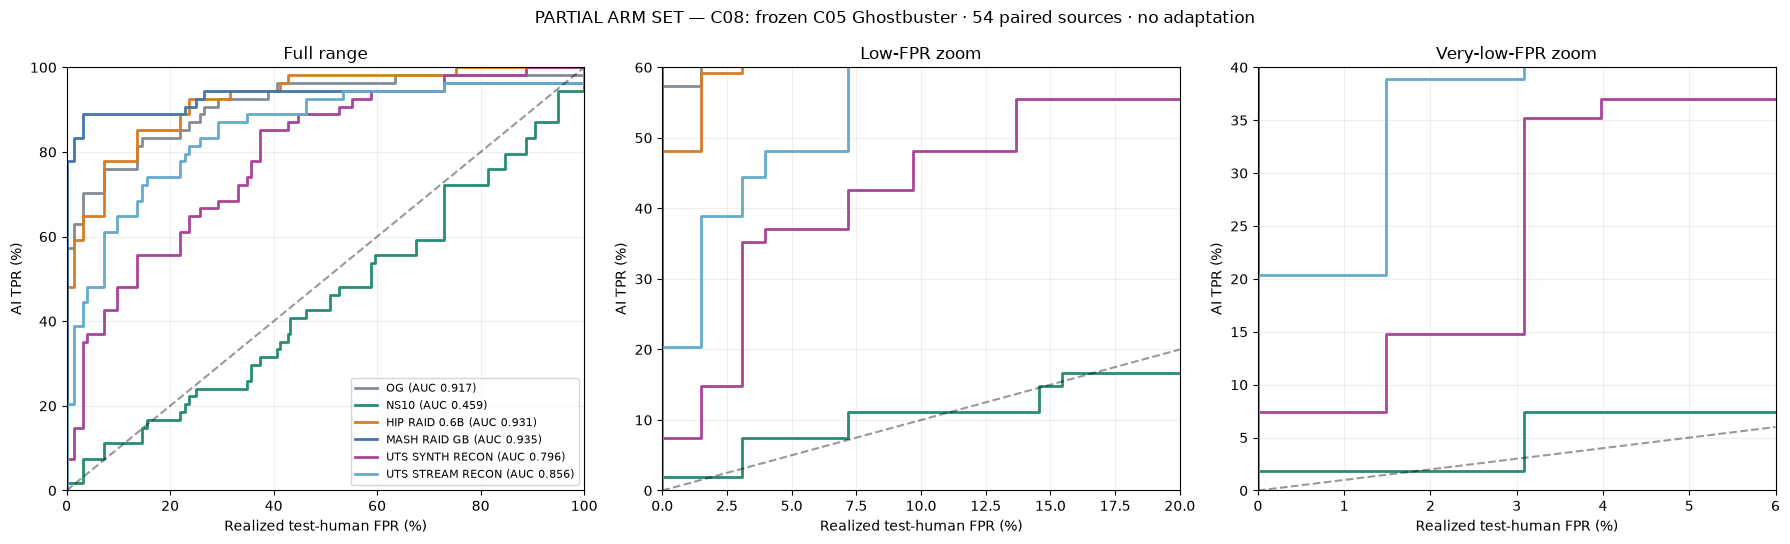

Pending arms (not silently dropped from the experiment): ['StealthRL_RAID_GB']
UTS *_RECON arms are procedure/prompt reconstructions, not exact competition submissions.
All completed outputs including token-capped outputs retained. Human references used only for evaluation.
Saved under: ../results/causal/C08_Ghostbuster_only_RAID54_v1


In [21]:
with run_lock():
    completion = export_and_score()
    plot_c08()
print('Saved under:', OUT)

Shared eligible subset: 25/54 cases


,retained,original
domain,,
abstracts,0,10
books,3,7
news,4,12
recipes,6,9
reddit,5,6
reviews,0,1
wiki,7,9


,arm,cases,AUROC,mean_AI_score,median_AI_score
0,OG,25,0.91051,0.75410,0.86745
1,NS10,25,0.45026,0.19745,0.13592
2,HIP_RAID_0.6B,25,0.91662,0.67474,0.60100
3,MASH_RAID_GB,25,0.95581,0.87124,0.97827
4,UTS_SYNTH_RECON,25,0.78253,0.44847,0.40394
5,UTS_STREAM_RECON,25,0.90582,0.58430,0.58405


,requested_FPR,threshold,calibration_FPR,test_FPR,OG,NS10,HIP_RAID_0.6B,MASH_RAID_GB,UTS_SYNTH_RECON,UTS_STREAM_RECON
0,0.00,0.8185,0.0000,0.0000,0.64,0.00,0.36,0.80,0.12,0.12
1,0.01,0.8185,0.0000,0.0000,0.64,0.00,0.36,0.80,0.12,0.12
2,0.02,0.7080,0.0114,0.0239,0.64,0.00,0.44,0.88,0.12,0.36
3,0.05,0.5744,0.0498,0.0532,0.80,0.08,0.68,0.88,0.32,0.56
4,0.10,0.5172,0.0957,0.0835,0.80,0.12,0.72,0.88,0.40,0.72
5,0.20,0.3732,0.1914,0.1839,0.84,0.20,0.88,0.92,0.52,0.84
6,0.50,0.1977,0.4950,0.3789,0.92,0.32,0.96,0.96,0.84,0.88
7,1.00,-inf,1.0000,1.0000,1.00,1.00,1.00,1.00,1.00,1.00


,arm,baseline,cases,delta_AUROC,ci_low,ci_high,lower_AI_score,higher_AI_score
0,NS10,OG,25,-0.46025,-0.60625,-0.30100,24,1
1,HIP_RAID_0.6B,OG,25,0.00611,-0.05610,0.10416,19,6
2,HIP_RAID_0.6B,NS10,25,0.46636,0.33974,0.59363,2,23
3,MASH_RAID_GB,OG,25,0.04530,-0.05827,0.16406,11,14
4,MASH_RAID_GB,NS10,25,0.50556,0.37276,0.63657,1,24
5,UTS_SYNTH_RECON,OG,25,-0.12798,-0.23010,-0.01788,21,4
6,UTS_SYNTH_RECON,NS10,25,0.33227,0.20403,0.46259,5,20
7,UTS_STREAM_RECON,OG,25,-0.00469,-0.10175,0.11041,19,6
8,UTS_STREAM_RECON,NS10,25,0.45557,0.31785,0.58830,4,21


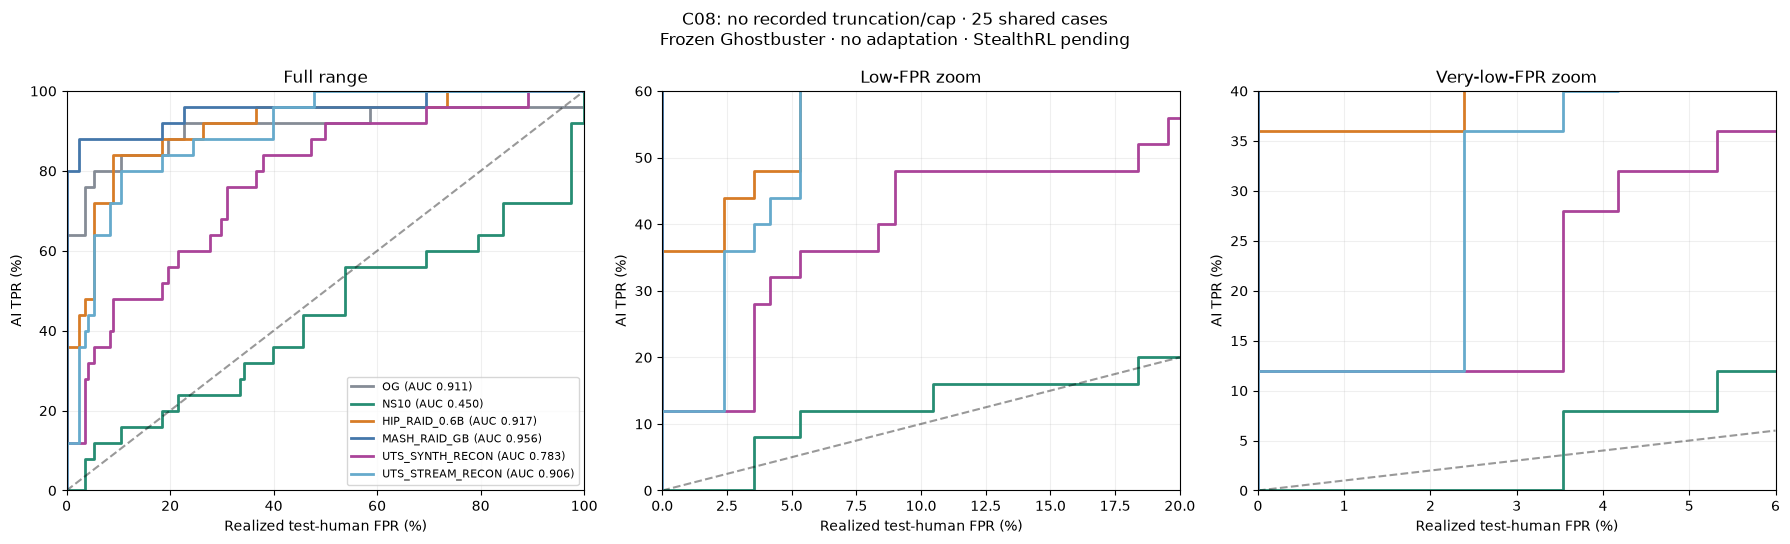

Saved: ../results/causal/C08_Ghostbuster_only_RAID54_v1/fair_play_nontruncated


In [22]:
# C08: matched comparison excluding recorded truncations/output caps.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def c08_fair_play():
    arms = [
        "HIP_RAID_0.6B", "MASH_RAID_GB",
        "UTS_SYNTH_RECON", "UTS_STREAM_RECON",
    ]
    destination = OUT / "fair_play_nontruncated"
    destination.mkdir(parents=True, exist_ok=True)

    ids = og.case_id.astype(str).tolist()
    audit = og[["case_id", "source_id", "domain"]].copy()
    audit["case_id"] = audit.case_id.astype(str)
    audit = audit.set_index("case_id").loc[ids]
    tables = {}

    def parse_bool(column):
        values = column.astype(str).str.strip().str.lower()
        assert values.isin(["true", "false", "1", "0"]).all(), (
            "Missing or unrecognized truncation flags."
        )
        return values.isin(["true", "1"])

    for arm in arms:
        frame = pd.read_csv(
            OUT / f"{arm}_scores.csv", dtype={"case_id": str}
        ).set_index("case_id")
        assert frame.index.is_unique and set(frame.index) == set(ids)
        frame = frame.loc[ids]
        assert frame.source_id.tolist() == audit.source_id.tolist()

        audit[f"{arm}:input_truncated"] = parse_bool(frame.input_truncated)
        audit[f"{arm}:output_capped"] = frame.stop_reason.astype(
            str
        ).str.lower().isin(["token_cap", "truncated", "length", "max_length"])
        tables[arm] = frame

    flag_columns = [c for c in audit if ":" in c]
    audit["included"] = ~audit[flag_columns].any(axis=1)
    audit["exclusion_reasons"] = audit[flag_columns].apply(
        lambda row: "; ".join(row.index[row.to_numpy(dtype=bool)]), axis=1
    )
    audit.reset_index().to_csv(destination / "case_selection.csv", index=False)

    keep = audit.included.to_numpy()
    n = int(keep.sum())
    print(f"Shared eligible subset: {n}/{len(ids)} cases")
    display(audit.groupby("domain").included.agg(["sum", "count"]).rename(
        columns={"sum": "retained", "count": "original"}
    ))
    if n < 2:
        print("Too few shared eligible cases for this comparison.")
        return

    series = {
        "OG": np.asarray(OG_SCORES)[keep],
        "NS10": np.asarray(NS10_SCORES)[keep],
        **{arm: tables[arm].AI_score.to_numpy()[keep] for arm in arms},
    }
    assert all(np.isfinite(v).all() for v in series.values())

    # Match human-reference genre weights to the retained cohort.
    mix = audit.loc[audit.included, "domain"].value_counts(normalize=True)

    def reference(split):
        mask = (
            raid.split.eq(split) & raid.label.eq(0)
            & raid.domain.isin(mix.index)
        )
        domains = raid.loc[mask, "domain"]
        counts = domains.value_counts()
        assert set(mix.index) <= set(counts.index)
        weights = np.array([mix[g] / counts[g] for g in domains])
        assert np.isclose(weights.sum(), 1)
        return np.asarray(GB.raid_scores)[mask.to_numpy()], weights

    cal, wc = reference("validation")
    human, wh = reference("test")

    def case_auc(scores):
        return np.array([
            wh[human < x].sum() + .5 * wh[human == x].sum()
            for x in scores
        ])

    summary = pd.DataFrame([
        dict(
            arm=name, cases=n, AUROC=case_auc(scores).mean(),
            mean_AI_score=scores.mean(), median_AI_score=np.median(scores),
        )
        for name, scores in series.items()
    ])
    display(summary.round(5))
    summary.to_csv(destination / "stage_summary.csv", index=False)

    cuts = np.r_[np.inf, np.unique(cal)[::-1], -np.inf]
    staircase = pd.DataFrame({
        "threshold": cuts,
        "calibration_FPR": [wc[cal > c].sum() for c in cuts],
        "test_FPR": [wh[human > c].sum() for c in cuts],
        **{
            name: [(scores > c).mean() for c in cuts]
            for name, scores in series.items()
        },
    })
    staircase.to_csv(destination / "TPR_staircase.csv", index=False)

    operating = pd.DataFrame([
        dict(
            requested_FPR=b,
            **staircase.loc[
                staircase.calibration_FPR <= b + 1e-12
            ].iloc[-1].to_dict(),
        )
        for b in [0, .01, .02, .05, .10, .20, .50, 1.]
    ])
    display(operating.round(4))
    operating.to_csv(destination / "operating_points.csv", index=False)

    # Paired case-bootstrap intervals, holding human references fixed.
    draws = np.random.default_rng(SEED).integers(0, n, size=(5000, n))
    comparisons = []
    for name, scores in series.items():
        for baseline in ["OG", "NS10"]:
            if name == baseline or name == "OG":
                continue
            delta = case_auc(scores) - case_auc(series[baseline])
            boot = delta[draws].mean(axis=1)
            comparisons.append(dict(
                arm=name, baseline=baseline, cases=n,
                delta_AUROC=delta.mean(),
                ci_low=np.quantile(boot, .025),
                ci_high=np.quantile(boot, .975),
                lower_AI_score=int((scores < series[baseline]).sum()),
                higher_AI_score=int((scores > series[baseline]).sum()),
            ))
    comparisons = pd.DataFrame(comparisons)
    display(comparisons.round(5))
    comparisons.to_csv(destination / "paired_comparisons.csv", index=False)

    colors = ["#858C96", "#278D73", "#D77C27",
              "#4477AA", "#AA4499", "#66AACC"]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    panels = [
        ((0, 100), (0, 100), "Full range"),
        ((0, 20), (0, 60), "Low-FPR zoom"),
        ((0, 6), (0, 40), "Very-low-FPR zoom"),
    ]
    for ax, (xlim, ylim, title) in zip(axes, panels):
        for (name, scores), color in zip(series.items(), colors):
            ax.step(
                staircase.test_FPR * 100, staircase[name] * 100,
                where="post", color=color, linewidth=2,
                label=f"{name} (AUC {case_auc(scores).mean():.3f})",
            )
        upper = min(xlim[1], ylim[1])
        ax.plot([0, upper], [0, upper], "k--", alpha=.4)
        ax.set(
            xlim=xlim, ylim=ylim, title=title,
            xlabel="Realized test-human FPR (%)", ylabel="AI TPR (%)",
        )
        ax.grid(alpha=.2)

    axes[0].legend(fontsize=8, loc="lower right")
    fig.suptitle(
        f"C08: no recorded truncation/cap · {n} shared cases"
        "\nFrozen Ghostbuster · no adaptation · StealthRL pending"
    )
    fig.tight_layout()
    for extension in ["png", "pdf"]:
        fig.savefig(
            destination / f"C08_fair_play.{extension}",
            dpi=250, bbox_inches="tight",
        )
    plt.show()
    plt.close(fig)
    print("Saved:", destination)

c08_fair_play()

## Handoff
- `C08_all_rewrites.csv`: final outputs and provenance, reusable for later hidden-detector evaluations.
- `<arm>_texts.csv`, `<arm>_scores.csv`, `<arm>_features.csv`: per-method texts and frozen-GB results.
- `manual_review.csv`: OG, NS10 and attack text side by side.
- `completion_status.csv`: explicit completion, token-cap and input-truncation counts.
- `stage_summary.csv`, `operating_points.csv`, `paired_comparisons.csv`, and `figures/`: comparison outputs.
- `models/`, `training/`, `cache/`: restartable checkpoints, training-only pairs, intermediate rounds and scoring caches.

Interpret lower detector scores as evasion; they do not by themselves establish semantic preservation or human-band
alignment. Smaller training resources, local generator substitutions, truncation and UTS prompt reconstruction are
part of this experiment's scope and should accompany any paper comparison. No adaptive detector is trained here.

### Primary sources checked for this notebook
- MASH: https://aclanthology.org/2026.findings-acl.1487/ ; https://arxiv.org/html/2601.08564
  ; https://github.com/githigher/MASH (style SFT, hard-negative DPO and refinement source inspected).
- StealthRL: https://arxiv.org/abs/2602.08934v2 ; https://github.com/suraj-ranganath/StealthRL
  (`configs/tinker_mage_10k.yaml`, training environment and standard few-shot prefix inspected).
- HIP: https://arxiv.org/abs/2605.19516 ; https://github.com/YixuanEvenXu/humanization-by-iterative-paraphrasing
  (training, inference, prompt format and 0.6B configuration inspected).
- UTS: https://clef-staging.pages.dev/paper102.pdf , §§4.3 and 4.7.
  Exact released prompt files were not located; `*_RECON` arms are explicitly reconstructed.

No actual model training or RAID scoring has been executed in the artifact-authoring environment.
Validation here covers notebook syntax, cache/resume bookkeeping, input identity checks and metric calculations.

In [14]:
import os, json, gc, hashlib, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftConfig, PeftModel
from huggingface_hub import HfApi
from sklearn.metrics import roc_curve, auc
from IPython.display import display

required = ['OUT','og','ns','GB','raid','OG_SCORES','NS10_SCORES','SEED','run_lock','atomic_csv']
missing = [x for x in required if x not in globals()]
assert not missing, f'Append these cells to C08 and run its setup + frozen Ghostbuster setup first. Missing: {missing}'
assert len(og)==54 and og.case_id.is_unique
assert torch.cuda.is_available(), 'This inference configuration requires CUDA.'
PUBOUT = Path(OUT)/'released_checkpoints_v1'
(PUBOUT/'figures').mkdir(parents=True, exist_ok=True)
PUB = {
 'HIP_RELEASED_4B': dict(adapter='YixuanEvenXu/Qwen3-4B-HIP-adapter', rounds=10,
     max_input=1024, max_new=1024, temperature=1.0, top_p=.95),
 'StealthRL_RELEASED_4B': dict(adapter='suraj-ranganath/StealthRL', rounds=1,
     max_input=1024, max_new=512, temperature=.9, top_p=.95),
}
# HIP: official inference.py defaults; no 4B-specific inference YAML found.
# StealthRL: official eval/methods/stealthrl.py local inference defaults.
PUB_ARMS = list(PUB)
def pub_read(p):
    return json.loads(Path(p).read_text()) if Path(p).exists() else None
def pub_write(p, value):
    p=Path(p); p.parent.mkdir(parents=True,exist_ok=True)
    tmp=p.with_suffix(p.suffix+'.tmp')
    with tmp.open('w') as f:
        json.dump(value,f,ensure_ascii=False,indent=2);f.flush();os.fsync(f.fileno())
    os.replace(tmp,p)
def pub_sha(s): return hashlib.sha256(str(s).encode()).hexdigest()
def pub_revision(repo):
    p=PUBOUT/'revisions.json'; saved=pub_read(p) or {}
    if repo not in saved:
        saved[repo]=HfApi().model_info(repo).sha;pub_write(p,saved)
    return saved[repo]
def pub_manifest(arm):
    p=PUBOUT/arm/'manifest.json'
    old=pub_read(p)
    inputs=[dict(case_id=str(r.case_id),source_id=str(r.source_id),text_sha=pub_sha(r.text)) for r in og.itertuples()]
    spec=dict(settings=PUB[arm],inputs=inputs,seed=int(SEED),quantization='NF4 double-quant; batch=1',procedure_version=1)
    if old:
        assert old['spec']==spec, 'Inputs/settings changed. Choose a new PUBOUT to keep both experiments.'
        return old
    cfg=PeftConfig.from_pretrained(PUB[arm]['adapter'],revision=pub_revision(PUB[arm]['adapter']))
    base=cfg.base_model_name_or_path
    assert base and not base.startswith(('/', './', '../')) and base.count('/')==1, f'Adapter declares a local/ambiguous base: {base!r}. Resolve against the author before substituting.'
    result=dict(spec=spec,base=base,base_revision=pub_revision(base),adapter_revision=pub_revision(PUB[arm]['adapter']))
    pub_write(p,result);return result
print('New outputs:',PUBOUT)
print('No training. NF4 4-bit inference; one 4B model at a time. Existing C08 outputs are retained.')


New outputs: ../results/causal/C08_Ghostbuster_only_RAID54_v1/released_checkpoints_v1
No training. NF4 4-bit inference; one 4B model at a time. Existing C08 outputs are retained.


In [15]:
def pub_load(arm, manifest):
    gc.collect();torch.cuda.empty_cache()
    dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    cfg=PUB[arm]
    tok_repo=cfg['adapter'] if arm.startswith('HIP') else manifest['base']
    tok_rev=manifest['adapter_revision'] if arm.startswith('HIP') else manifest['base_revision']
    tok=AutoTokenizer.from_pretrained(tok_repo,revision=tok_rev,use_fast=True)
    if tok.pad_token_id is None:tok.pad_token=tok.eos_token
    tok.padding_side='left'
    quant=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
        bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=dtype)
    base=AutoModelForCausalLM.from_pretrained(manifest['base'],revision=manifest['base_revision'],
        quantization_config=quant,torch_dtype=dtype,device_map={'':0},
        low_cpu_mem_usage=True,attn_implementation='sdpa')
    model=PeftModel.from_pretrained(base,cfg['adapter'],revision=manifest['adapter_revision'],is_trainable=False)
    model.eval();model.requires_grad_(False)
    return model,tok,dtype

STEALTH_PROMPT = '''Please paraphrase the following text while maintaining its meaning and style. Keep the paraphrase close to the original length, do not add new details, and output only the paraphrased text without any additional explanation.

Original text:
{text}

Paraphrased text:'''
def pub_prompt(arm,text,tok):
    if arm.startswith('HIP'):
        return '<source_text>\n'+str(text).strip()+'\n</source_text>\n\n<target_text>\n'
    return tok.apply_chat_template([dict(role='user',content=STEALTH_PROMPT.format(text=text))],
        tokenize=False,add_generation_prompt=True)
def pub_clean(arm,text,source):
    text=text.strip()
    if arm.startswith('HIP'):
        if text.startswith('<target_text>'):text=text[len('<target_text>'):].lstrip()
        if '</target_text>' in text:text=text.split('</target_text>',1)[0].rstrip()
        return text.strip(),False
    # The author's local runner returns the source when no nonempty candidate is obtained.
    return (text,False) if text else (source,True)
def pub_sample(arm,source,model,tok,dtype,seed):
    cfg=PUB[arm];prompt=pub_prompt(arm,source,tok)
    count=len(tok(prompt)['input_ids'])
    encoded=tok(prompt,return_tensors='pt',truncation=True,max_length=cfg['max_input']).to('cuda:0')
    kwargs=dict(max_new_tokens=cfg['max_new'],do_sample=True,temperature=cfg['temperature'],
        top_p=cfg['top_p'],pad_token_id=tok.pad_token_id,use_cache=True)
    if arm.startswith('HIP'):kwargs['eos_token_id']=tok.eos_token_id
    torch.manual_seed(seed);torch.cuda.manual_seed_all(seed)
    start=time.monotonic()
    with torch.inference_mode(),torch.autocast('cuda',dtype=dtype):
        seq=model.generate(**encoded,**kwargs)
    ids=seq[0,encoded.input_ids.shape[1]:].detach().cpu().tolist()
    raw=tok.decode(ids,skip_special_tokens=True)
    text,fallback=pub_clean(arm,raw,source)
    eos=kwargs.get('eos_token_id',model.generation_config.eos_token_id)
    eos=[] if eos is None else ([eos] if isinstance(eos,int) else list(eos))
    cap=len(ids)>=cfg['max_new'] and (not ids or ids[-1] not in eos)
    return dict(text=text,raw_output=raw,token_ids=ids,input_tokens=count,
        input_truncated=count>cfg['max_input'],token_cap=cap,empty_fallback=fallback,
        seconds=time.monotonic()-start,seed=seed)

def pub_final(arm,r):
    d=pub_read(PUBOUT/arm/'final'/f'{r.case_id}.json')
    if d:assert d['source_sha']==pub_sha(r.text), 'Saved output belongs to another source.'
    return d

def run_published(arm):
    manifest=pub_manifest(arm)
    todo=[r for r in og.itertuples(index=False) if pub_final(arm,r) is None]
    print(f'{arm}: {len(todo)}/54 remaining',flush=True)
    if not todo:return
    model=tok=None
    try:
        model,tok,dtype=pub_load(arm,manifest)
        for r in todo:
            source=str(r.text).strip();records=[]
            for k in range(PUB[arm]['rounds']):
                p=PUBOUT/arm/'rounds'/str(r.case_id)/f'{k+1:02d}.json'
                record=pub_read(p)
                if record:
                    assert record['input_sha']==pub_sha(source), 'Saved round has a different input.'
                else:
                    seed=(int(SEED)+int(pub_sha(f'{arm}/{r.case_id}/{k}')[:8],16))%(2**31)
                    record=pub_sample(arm,source,model,tok,dtype,seed)
                    record.update(input_sha=pub_sha(source),round=k+1)
                    pub_write(p,record)
                    print(f'{arm} {r.case_id}: round {k+1}/{PUB[arm]["rounds"]} saved; cap={record["token_cap"]}',flush=True)
                records.append(record);source=record['text']
            result=dict(arm=arm,case_id=str(r.case_id),source_id=str(r.source_id),domain=str(r.domain),
                source_sha=pub_sha(r.text),text=source,text_sha=pub_sha(source),
                input_truncated=any(d['input_truncated'] for d in records),
                token_cap=any(d['token_cap'] for d in records),final_token_cap=records[-1]['token_cap'],
                empty_fallback=any(d['empty_fallback'] for d in records),
                seconds=sum(d['seconds'] for d in records),rounds=len(records))
            pub_write(PUBOUT/arm/'final'/f'{r.case_id}.json',result)
            print(f'{arm}: {r.case_id} final saved',flush=True)
    finally:
        del model,tok
        gc.collect();torch.cuda.empty_cache()
    print('Inference finished. Run evaluation after both arms.',flush=True)


In [16]:
with run_lock():
    run_published('HIP_RELEASED_4B')


HIP_RELEASED_4B: 54/54 remaining


Loading checkpoint shards: 100%|█| 3/3 [00:07<00:00,  2.40s/


HIP_RELEASED_4B gate_0001: round 1/10 saved; cap=False
HIP_RELEASED_4B gate_0001: round 2/10 saved; cap=False
HIP_RELEASED_4B gate_0001: round 3/10 saved; cap=False
HIP_RELEASED_4B gate_0001: round 4/10 saved; cap=False
HIP_RELEASED_4B gate_0001: round 5/10 saved; cap=False
HIP_RELEASED_4B gate_0001: round 6/10 saved; cap=False
HIP_RELEASED_4B gate_0001: round 7/10 saved; cap=False
HIP_RELEASED_4B gate_0001: round 8/10 saved; cap=False
HIP_RELEASED_4B gate_0001: round 9/10 saved; cap=False
HIP_RELEASED_4B gate_0001: round 10/10 saved; cap=False
HIP_RELEASED_4B: gate_0001 final saved
HIP_RELEASED_4B gate_0003: round 1/10 saved; cap=False
HIP_RELEASED_4B gate_0003: round 2/10 saved; cap=False
HIP_RELEASED_4B gate_0003: round 3/10 saved; cap=False
HIP_RELEASED_4B gate_0003: round 4/10 saved; cap=False
HIP_RELEASED_4B gate_0003: round 5/10 saved; cap=False
HIP_RELEASED_4B gate_0003: round 6/10 saved; cap=False
HIP_RELEASED_4B gate_0003: round 7/10 saved; cap=False
HIP_RELEASED_4B gate_0003

In [17]:
with run_lock():
    run_published('StealthRL_RELEASED_4B')


StealthRL_RELEASED_4B: 54/54 remaining


Loading checkpoint shards: 100%|███████████████████████████████████████████████████████████████| 3/3 [00:09<00:00,  3.03s/it]


StealthRL_RELEASED_4B gate_0001: round 1/1 saved; cap=False
StealthRL_RELEASED_4B: gate_0001 final saved
StealthRL_RELEASED_4B gate_0003: round 1/1 saved; cap=False
StealthRL_RELEASED_4B: gate_0003 final saved
StealthRL_RELEASED_4B gate_0004: round 1/1 saved; cap=False
StealthRL_RELEASED_4B: gate_0004 final saved
StealthRL_RELEASED_4B gate_0005: round 1/1 saved; cap=False
StealthRL_RELEASED_4B: gate_0005 final saved
StealthRL_RELEASED_4B gate_0007: round 1/1 saved; cap=False
StealthRL_RELEASED_4B: gate_0007 final saved
StealthRL_RELEASED_4B gate_0015: round 1/1 saved; cap=False
StealthRL_RELEASED_4B: gate_0015 final saved
StealthRL_RELEASED_4B gate_0016: round 1/1 saved; cap=False
StealthRL_RELEASED_4B: gate_0016 final saved
StealthRL_RELEASED_4B gate_0017: round 1/1 saved; cap=False
StealthRL_RELEASED_4B: gate_0017 final saved
StealthRL_RELEASED_4B gate_0018: round 1/1 saved; cap=False
StealthRL_RELEASED_4B: gate_0018 final saved
StealthRL_RELEASED_4B gate_0019: round 1/1 saved; cap=F

In [18]:
def score_published():
    status=[];all_frames=[]
    for arm in PUB_ARMS:
        pub_manifest(arm)  # validate inputs/settings even when generation cells were skipped
        rows=[d for r in og.itertuples(index=False) if (d:=pub_final(arm,r)) is not None]
        status.append(dict(arm=arm,completed=len(rows),requested=54,
            any_round_input_truncated=sum(d['input_truncated'] for d in rows),
            any_round_token_cap=sum(d['token_cap'] for d in rows),
            final_token_cap=sum(d['final_token_cap'] for d in rows)))
        if len(rows)!=54:continue
        f=pd.DataFrame(rows).set_index('case_id').loc[og.case_id].reset_index()
        assert f.text.str.strip().ne('').all(), f'{arm}: empty output; inspect saved raw output before scoring.'
        atomic_csv(PUBOUT/(arm+'_texts.csv'),f)
        scores=GB.score(f.text.tolist(),purpose='released_final_frozen_evaluation/'+arm)
        f['AI_score']=scores
        atomic_csv(PUBOUT/(arm+'_scores.csv'),f)
        all_frames.append(f)
    status=pd.DataFrame(status);atomic_csv(PUBOUT/'completion_status.csv',status);display(status)
    if all_frames:
        review=pd.concat(all_frames,ignore_index=True)
        review=review.merge(og[['case_id','text']].rename(columns={'text':'OG_text'}),on='case_id',validate='many_to_one')
        review=review.merge(ns[['case_id','text']].rename(columns={'text':'NS10_text'}),on='case_id',validate='many_to_one')
        atomic_csv(PUBOUT/'manual_review.csv',review)
    return status


In [19]:
import matplotlib.pyplot as plt
def plot_published():
    # Only complete 54-case arms enter the final comparison. No casewise cherry-picking.
    series={'OG':OG_SCORES,'NS10':NS10_SCORES};pending=[]
    for arm in PUB_ARMS:
        p=PUBOUT/(arm+'_scores.csv')
        if p.exists():
            f=pd.read_csv(p).set_index('case_id')
            if set(f.index)==set(og.case_id) and len(f)==54:
                series[arm]=f.loc[og.case_id,'AI_score'].to_numpy();continue
        pending.append(arm)
    mix=og.domain.value_counts(normalize=True)
    def reference(split):
        mask=raid.split.eq(split)&raid.label.eq(0)&raid.domain.isin(mix.index)
        frame=raid.loc[mask];counts=frame.domain.value_counts()
        assert set(mix.index)<=set(counts.index)
        w=np.array([mix[g]/counts[g] for g in frame.domain]);assert np.isclose(w.sum(),1)
        return GB.raid_scores[mask.to_numpy()],w
    cal,wc=reference('validation');human,wh=reference('test')
    cuts=np.r_[np.inf,np.unique(cal)[::-1],-np.inf]
    st=pd.DataFrame(dict(threshold=cuts,calibration_FPR=[wc[cal>c].sum() for c in cuts],
        test_FPR=[wh[human>c].sum() for c in cuts]))
    for arm,scores in series.items():st[arm]=[(scores>c).mean() for c in cuts]
    atomic_csv(PUBOUT/'C08_frozen_Ghostbuster_TPR_staircase.csv',st)
    def au(scores):
        f,t,_=roc_curve(np.r_[np.zeros(len(human)),np.ones(len(scores))],np.r_[human,scores],
            sample_weight=np.r_[wh,np.ones(len(scores))/len(scores)],drop_intermediate=False)
        return float(auc(f,t))
    summary=pd.DataFrame([dict(arm=k,cases=54,AUROC=au(v),mean_AI_score=float(v.mean()),
                              median_AI_score=float(np.median(v))) for k,v in series.items()])
    atomic_csv(PUBOUT/'stage_summary.csv',summary);display(summary.round(5))
    budgets=[0,.001,.005,.01,.02,.03,.04,.05,.075,.1,.15,.2,.3,.4,.5,1.]
    op=[]
    for b in budgets:
        r=st.loc[st.calibration_FPR<=b+1e-12].iloc[-1]
        op.append(dict(requested_FPR=b,**r.to_dict()))
    atomic_csv(PUBOUT/'operating_points.csv',pd.DataFrame(op));display(pd.DataFrame(op).round(4))
    # Paired AI-case bootstrap; same human reference weights and fixed trained models.
    rng=np.random.default_rng(SEED);draws=rng.integers(0,54,size=(5000,54))
    paired=[]
    for name,s in series.items():
        if name=='OG':continue
        for baseline in ['OG','NS10']:
            if name==baseline:continue
            # AUROC is mean weighted human CDF at each AI score (half credit for ties).
            def case_auc(a):return np.array([wh[human<x].sum()+.5*wh[human==x].sum() for x in a])
            delta=case_auc(s)-case_auc(series[baseline]);boot=delta[draws].mean(1)
            paired.append(dict(arm=name,baseline=baseline,delta_AUROC=float(delta.mean()),
                ci_low=float(np.quantile(boot,.025)),ci_high=float(np.quantile(boot,.975)),
                lower_AI_score=int((s<series[baseline]).sum()),higher_AI_score=int((s>series[baseline]).sum())))
    atomic_csv(PUBOUT/'paired_comparisons.csv',pd.DataFrame(paired));display(pd.DataFrame(paired).round(5))
    colors=['#858C96','#278D73','#D77C27','#4477AA','#AA4499','#66AACC','#AA7744']
    fig,axes=plt.subplots(1,3,figsize=(18,5.5))
    for ax,(xlim,ylim,title) in zip(axes,[((0,100),(0,100),'Full range'),((0,20),(0,60),'Low-FPR zoom'),((0,6),(0,40),'Very-low-FPR zoom')]):
        for (name,s),color in zip(series.items(),colors):
            label=name.replace('_',' ')+f' (AUC {au(s):.3f})'
            ax.step(st.test_FPR*100,st[name]*100,where='post',label=label,color=color,lw=2)
        m=min(xlim[1],ylim[1]);ax.plot([0,m],[0,m],'k--',alpha=.4)
        ax.set(xlim=xlim,ylim=ylim,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)',title=title);ax.grid(alpha=.2)
    axes[0].legend(fontsize=8,loc='lower right')
    prefix='PARTIAL ARM SET — ' if pending else ''
    fig.suptitle(prefix+'C08 released checkpoints: frozen C05 Ghostbuster · 54 paired sources · no adaptation')
    fig.tight_layout()
    for ext in ['png','pdf']:fig.savefig(PUBOUT/'figures'/('C08_frozen_Ghostbuster.'+ext),dpi=250,bbox_inches='tight')
    plt.show();plt.close(fig)
    if pending:print('Pending arms (not silently dropped from the experiment):',pending)
    print('Released 4B adapters, NF4 inference; training overlap not audited. No adaptation.')
    print('All completed outputs including token-capped outputs retained. Human references used only for evaluation.')


Ghostbuster released_final_frozen_evaluation/HIP_RELEASED_4B: ada 1/54
Ghostbuster released_final_frozen_evaluation/HIP_RELEASED_4B: ada 16/54
Ghostbuster released_final_frozen_evaluation/HIP_RELEASED_4B: ada 32/54
Ghostbuster released_final_frozen_evaluation/HIP_RELEASED_4B: ada 48/54
Ghostbuster released_final_frozen_evaluation/HIP_RELEASED_4B: davinci 1/54
Ghostbuster released_final_frozen_evaluation/HIP_RELEASED_4B: davinci 16/54
Ghostbuster released_final_frozen_evaluation/HIP_RELEASED_4B: davinci 32/54
Ghostbuster released_final_frozen_evaluation/HIP_RELEASED_4B: davinci 48/54
Tokenizing corpus...


100%|███████████████████████████████████████████████████████████████████████████████| 57340/57340 [00:02<00:00, 20334.94it/s]



Training n-gram model...


100%|██████████████████████████████████████████████████████████████████████████| 1283104/1283104 [00:02<00:00, 518411.55it/s]


Ghostbuster released_final_frozen_evaluation/StealthRL_RELEASED_4B: ada 1/54
Ghostbuster released_final_frozen_evaluation/StealthRL_RELEASED_4B: ada 16/54
Ghostbuster released_final_frozen_evaluation/StealthRL_RELEASED_4B: ada 32/54
Ghostbuster released_final_frozen_evaluation/StealthRL_RELEASED_4B: ada 48/54
Ghostbuster released_final_frozen_evaluation/StealthRL_RELEASED_4B: davinci 1/54
Ghostbuster released_final_frozen_evaluation/StealthRL_RELEASED_4B: davinci 16/54
Ghostbuster released_final_frozen_evaluation/StealthRL_RELEASED_4B: davinci 32/54
Ghostbuster released_final_frozen_evaluation/StealthRL_RELEASED_4B: davinci 48/54


,arm,completed,requested,any_round_input_truncated,any_round_token_cap,final_token_cap
0,HIP_RELEASED_4B,54,54,0,0,0
1,StealthRL_RELEASED_4B,54,54,0,0,0


,arm,cases,AUROC,mean_AI_score,median_AI_score
0,OG,54,0.91733,0.73836,0.83320
1,NS10,54,0.45893,0.21652,0.13685
2,HIP_RELEASED_4B,54,0.85342,0.55241,0.57589
3,StealthRL_RELEASED_4B,54,0.73666,0.58863,0.75462


,requested_FPR,threshold,calibration_FPR,test_FPR,OG,NS10,HIP_RELEASED_4B,StealthRL_RELEASED_4B
0,0.000,0.9242,0.0000,0.0000,0.3333,0.0000,0.0741,0.3889
1,0.001,0.9242,0.0000,0.0000,0.3333,0.0000,0.0741,0.3889
2,0.005,0.9242,0.0000,0.0000,0.3333,0.0000,0.0741,0.3889
3,0.010,0.8185,0.0084,0.0000,0.5741,0.0185,0.1296,0.4259
4,0.020,0.7080,0.0164,0.0149,0.6296,0.0185,0.2778,0.5185
5,0.030,0.7035,0.0256,0.0149,0.6296,0.0185,0.2963,0.5185
6,0.040,0.6208,0.0340,0.0309,0.7037,0.0741,0.4259,0.5185
7,0.050,0.5744,0.0499,0.0718,0.7222,0.0926,0.5000,0.5370
8,0.075,0.5624,0.0662,0.0718,0.7407,0.1111,0.5000,0.5370
9,0.100,0.5391,0.0924,0.0718,0.7593,0.1111,0.5556,0.5370


,arm,baseline,delta_AUROC,ci_low,ci_high,lower_AI_score,higher_AI_score
0,NS10,OG,-0.45840,-0.55157,-0.36659,49,5
1,HIP_RELEASED_4B,OG,-0.06391,-0.12549,0.00377,41,13
2,HIP_RELEASED_4B,NS10,0.39449,0.30424,0.48349,5,49
3,StealthRL_RELEASED_4B,OG,-0.18068,-0.27886,-0.08409,33,21
4,StealthRL_RELEASED_4B,NS10,0.27773,0.16680,0.39626,12,42


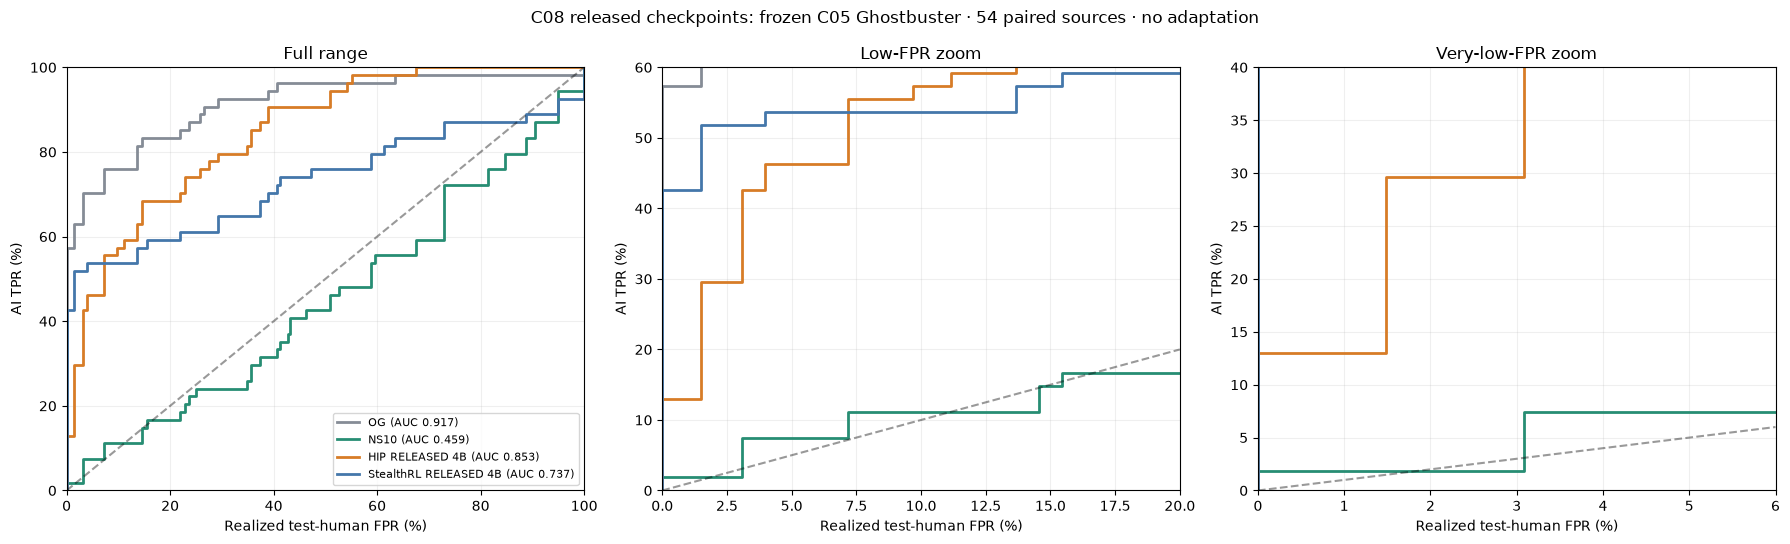

Released 4B adapters, NF4 inference; training overlap not audited. No adaptation.
All completed outputs including token-capped outputs retained. Human references used only for evaluation.
Saved results and figures: ../results/causal/C08_Ghostbuster_only_RAID54_v1/released_checkpoints_v1


In [20]:
with run_lock():
    published_status=score_published()
    plot_published()
print("Saved results and figures:", PUBOUT)


role,adaptation,heldout
domain,,
abstracts,5,5
books,3,4
news,3,9
recipes,5,4
reddit,2,4
reviews,0,1
wiki,2,7


UTS_SYNTH (limited): fitting on 1272 RAID rows + 20 own-arm texts...


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

StealthRL (released 4B): fitting on 1272 RAID rows + 20 own-arm texts...


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

,arm,detector,cases,AUROC,mean_AI_score,median_AI_score,AUROC_change_vs_frozen_pp
0,UTS_SYNTH (limited),Frozen,34,0.83336,0.51194,0.55686,0.00000
1,UTS_SYNTH (limited),Adapted,34,0.84175,0.53448,0.59353,0.83896
2,StealthRL (released 4B),Frozen,34,0.79578,0.67591,0.87461,0.00000
3,StealthRL (released 4B),Adapted,34,0.90989,0.78547,0.99124,11.41126


,arm,detector,requested_FPR,threshold,calibration_FPR,test_FPR,TPR
0,UTS_SYNTH (limited),Frozen,0.000,0.92422,0.00000,0.00000,0.02941
1,UTS_SYNTH (limited),Frozen,0.001,0.92422,0.00000,0.00000,0.02941
2,UTS_SYNTH (limited),Frozen,0.005,0.92422,0.00000,0.00000,0.02941
3,UTS_SYNTH (limited),Frozen,0.010,0.81855,0.00668,0.00000,0.05882
4,UTS_SYNTH (limited),Frozen,0.020,0.70800,0.01229,0.01296,0.14706
5,UTS_SYNTH (limited),Frozen,0.050,0.56887,0.04946,0.06032,0.50000
6,UTS_SYNTH (limited),Frozen,0.100,0.52671,0.09459,0.08291,0.55882
7,UTS_SYNTH (limited),Frozen,0.200,0.43112,0.19818,0.14145,0.58824
8,UTS_SYNTH (limited),Frozen,0.500,0.19982,0.49246,0.42847,0.91176
9,UTS_SYNTH (limited),Frozen,1.000,-inf,1.00000,1.00000,1.00000


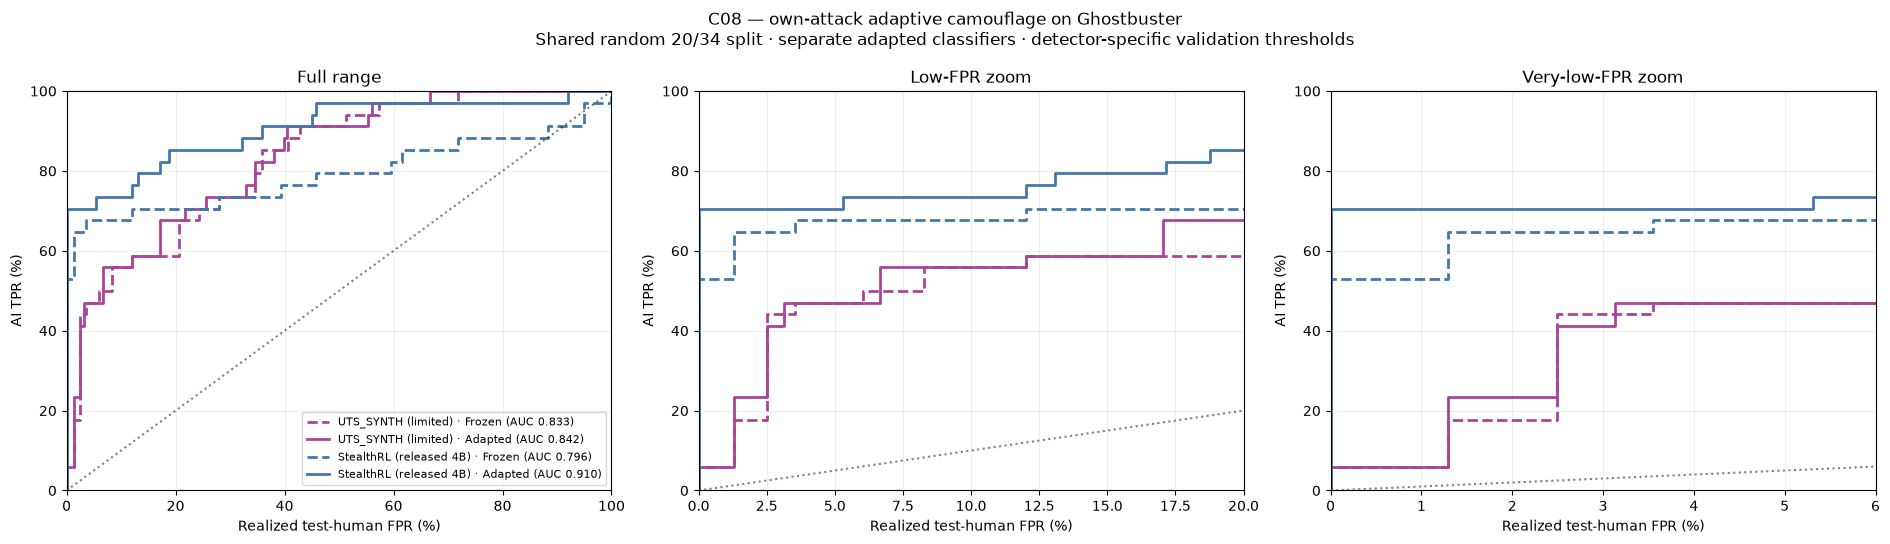

Saved: ../results/causal/C08_Ghostbuster_only_RAID54_v1/adaptive_competitors_20_34_v1
Frozen results here use the held-out 34, not the earlier full 54.


In [23]:
# C08 adaptive camouflage: UTS_SYNTH and released StealthRL
# Same 20/34 source split; separate adaptation for each attack.
import json, os, warnings
from pathlib import Path
import dill
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score

def c08_adaptive_competitors():
    base = Path(OUT)
    dest = base / "adaptive_competitors_20_34_v1"
    dest.mkdir(parents=True, exist_ok=True)

    def save_json(path, obj):
        tmp = path.with_suffix(path.suffix + ".tmp")
        with tmp.open("w") as f:
            json.dump(obj, f, indent=2)
            f.flush()
            os.fsync(f.fileno())
        os.replace(tmp, path)

    def save_model(path, model):
        tmp = path.with_suffix(".tmp")
        with tmp.open("wb") as f:
            dill.dump(model, f)
            f.flush()
            os.fsync(f.fileno())
        os.replace(tmp, path)

    cases = og.sort_values("case_id").reset_index(drop=True)
    assert len(cases) == 54 and cases.case_id.is_unique
    assert cases.source_id.is_unique

    # Persist a single shared split, reused on every rerun.
    split_path = dest / "split_20_34.csv"
    if split_path.exists():
        split = pd.read_csv(split_path)
        pd.testing.assert_frame_equal(
            split[["case_id", "source_id", "domain"]],
            cases[["case_id", "source_id", "domain"]],
            check_dtype=False,
        )
    else:
        split = cases[["case_id", "source_id", "domain"]].copy()
        split["role"] = "heldout"
        chosen = np.random.default_rng(SEED).choice(54, 20, replace=False)
        split.loc[chosen, "role"] = "adaptation"
        atomic_csv(split_path, split)

    ai = np.flatnonzero(split.role.eq("adaptation"))
    hi = np.flatnonzero(split.role.eq("heldout"))
    assert len(ai) == 20 and len(hi) == 34
    display(pd.crosstab(split.domain, split.role))

    # Same frozen representation and normalization as C06.
    Xraid = GB.rf.loc[
        "raid::" + raid.source_id.astype(str), GB.names
    ].to_numpy(float)
    Zraid = GB.normalize(Xraid, mu=GB.mu, sigma=GB.sigma)
    train = raid.split.eq("train").to_numpy()
    assert set(cases.source_id).isdisjoint(raid.loc[train, "source_id"])
    assert raid.set_index("source_id").loc[
        cases.source_id, "split"
    ].eq("test").all()

    # Human domain weights match the held-out 34.
    mix = cases.iloc[hi].domain.value_counts(normalize=True)

    def reference(split_name):
        mask = (
            raid.split.eq(split_name)
            & raid.label.eq(0)
            & raid.domain.isin(mix.index)
        ).to_numpy()
        domains = raid.loc[mask, "domain"]
        counts = domains.value_counts()
        assert set(mix.index).issubset(counts.index)
        weights = np.array([mix[d] / counts[d] for d in domains])
        assert np.isclose(weights.sum(), 1)
        return mask, weights

    cm, wc = reference("validation")
    hm, wh = reference("test")

    released = Path(
        globals().get("PUBOUT", base / "released_checkpoints_v1")
    )
    arms = {
        "UTS_SYNTH (limited)": (
            "UTS_SYNTH_RECON",
            base / "UTS_SYNTH_RECON_texts.csv",
        ),
        "StealthRL (released 4B)": (
            "StealthRL_RELEASED_4B",
            released / "StealthRL_RELEASED_4B_texts.csv",
        ),
    }

    curves, summary, operating = {}, [], []
    for label, (arm, path) in arms.items():
        assert path.exists(), f"Missing saved rewrites: {path}"
        frame = pd.read_csv(path, keep_default_na=False)
        assert len(frame) == 54 and frame.case_id.is_unique
        assert set(frame.case_id) == set(cases.case_id)
        frame = frame.set_index("case_id").loc[cases.case_id].reset_index()
        assert frame.source_id.astype(str).tolist() == cases.source_id.astype(str).tolist()
        assert frame.domain.tolist() == cases.domain.tolist()
        assert frame.text.str.strip().ne("").all()

        folder = dest / arm
        folder.mkdir(exist_ok=True)

        # Uses existing C08 feature caches; computes only missing features.
        frozen_scores = np.asarray(
            GB.score(frame.text.tolist(), purpose=f"C08_adaptation/{arm}")
        )
        X = np.array([
            json.loads(Path(GB.path(t, "features")).read_text())["features"]
            for t in frame.text
        ], dtype=float)
        assert np.isfinite(X).all()
        Z = GB.normalize(X, mu=GB.mu, sigma=GB.sigma)
        np.testing.assert_allclose(
            GB.model.predict_proba(Z)[:, 1],
            frozen_scores,
            rtol=1e-7, atol=1e-9,
        )

        # Save the actual fitting inputs: no notebook-source hash dependency.
        Xfit = np.vstack([Zraid[train], Z[ai]])
        yfit = np.r_[
            raid.loc[train, "label"].to_numpy(int),
            np.ones(20, dtype=int),
        ]
        fit_path = folder / "fit_inputs.npz"
        if fit_path.exists():
            with np.load(fit_path) as previous:
                np.testing.assert_array_equal(previous["X"], Xfit)
                np.testing.assert_array_equal(previous["y"], yfit)
        else:
            tmp = folder / "fit_inputs.tmp"
            with tmp.open("wb") as f:
                np.savez_compressed(f, X=Xfit, y=yfit)
            os.replace(tmp, fit_path)

        manifest = dict(
            arm=arm, seed=int(SEED),
            adaptation_ids=cases.iloc[ai].case_id.tolist(),
            heldout_ids=cases.iloc[hi].case_id.tolist(),
            fit="Original RAID train + 20 own-arm positives; unit weights",
            representation="Frozen C05 features and normalization",
            classifier_parameters=repr(GB.model.get_params(deep=True)),
        )
        manifest_path = folder / "manifest.json"
        if manifest_path.exists():
            assert json.loads(manifest_path.read_text()) == manifest, (
                "Adaptation settings changed; use a new output directory."
            )
        else:
            save_json(manifest_path, manifest)

        model_path = folder / "adapted_ghostbuster.pkl"
        if model_path.exists():
            with model_path.open("rb") as f:
                adapted = dill.load(f)
            print(f"{label}: loaded saved adapted detector.")
        else:
            adapted = clone(GB.model)
            print(
                f"{label}: fitting on {train.sum()} RAID rows + 20 own-arm texts...",
                flush=True,
            )
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                adapted.fit(Xfit, yfit)
            save_model(model_path, adapted)
        assert list(adapted.classes_) == [0, 1]

        scores_out = cases.iloc[hi][
            ["case_id", "source_id", "domain"]
        ].copy()

        for detector, model in [("Frozen", GB.model), ("Adapted", adapted)]:
            cal = model.predict_proba(Zraid[cm])[:, 1]
            human = model.predict_proba(Zraid[hm])[:, 1]
            attack = model.predict_proba(Z[hi])[:, 1]

            auc_value = roc_auc_score(
                np.r_[np.zeros(len(human)), np.ones(34)],
                np.r_[human, attack],
                sample_weight=np.r_[wh, np.ones(34) / 34],
            )
            cuts = np.r_[np.inf, np.unique(cal)[::-1], -np.inf]
            st = pd.DataFrame({
                "threshold": cuts,
                "calibration_FPR": [wc[cal > c].sum() for c in cuts],
                "test_FPR": [wh[human > c].sum() for c in cuts],
                "TPR": [(attack > c).mean() for c in cuts],
            })
            curves[(label, detector)] = (st, auc_value)
            atomic_csv(folder / f"{detector}_staircase.csv", st)
            scores_out[f"{detector}_AI_score"] = attack

            for name, mask, weights, values in [
                ("validation", cm, wc, cal), ("test", hm, wh, human)
            ]:
                refs = raid.loc[mask, ["source_id", "domain"]].copy()
                refs["weight"] = weights
                refs["AI_score"] = values
                atomic_csv(folder / f"{detector}_{name}_humans.csv", refs)

            summary.append(dict(
                arm=label, detector=detector, cases=34,
                AUROC=auc_value,
                mean_AI_score=float(attack.mean()),
                median_AI_score=float(np.median(attack)),
            ))
            for target in [0, .001, .005, .01, .02, .05, .10, .20, .50, 1]:
                row = st.loc[
                    st.calibration_FPR <= target + 1e-12
                ].iloc[-1]
                operating.append(dict(
                    arm=label, detector=detector,
                    requested_FPR=target, **row.to_dict()
                ))

        atomic_csv(folder / "heldout34_scores.csv", scores_out)

    summary = pd.DataFrame(summary)
    frozen_auc = summary[summary.detector.eq("Frozen")].set_index("arm").AUROC
    summary["AUROC_change_vs_frozen_pp"] = 100 * (
        summary.AUROC - summary.arm.map(frozen_auc)
    )
    atomic_csv(dest / "summary.csv", summary)
    atomic_csv(dest / "operating_points.csv", pd.DataFrame(operating))
    display(summary.round(5))
    display(pd.DataFrame(operating).round(5))

    # One combined figure: both attacks × frozen/adapted.
    colors = {
        "UTS_SYNTH (limited)": "#AA4499",
        "StealthRL (released 4B)": "#4477AA",
    }
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
    views = [
        ((0, 100), (0, 100), "Full range"),
        ((0, 20), (0, 100), "Low-FPR zoom"),
        ((0, 6), (0, 100), "Very-low-FPR zoom"),
    ]
    for ax, (xlim, ylim, title) in zip(axes, views):
        for (label, detector), (st, value) in curves.items():
            ax.step(
                st.test_FPR * 100, st.TPR * 100, where="post",
                color=colors[label],
                linestyle="--" if detector == "Frozen" else "-",
                linewidth=2,
                label=f"{label} · {detector} (AUC {value:.3f})",
            )
        ax.plot([0, xlim[1]], [0, xlim[1]], "k:", alpha=.5)
        ax.set(
            xlim=xlim, ylim=ylim, title=title,
            xlabel="Realized test-human FPR (%)", ylabel="AI TPR (%)",
        )
        ax.grid(alpha=.2)

    axes[0].legend(fontsize=8, loc="lower right")
    fig.suptitle(
        "C08 — own-attack adaptive camouflage on Ghostbuster\n"
        "Shared random 20/34 split · separate adapted classifiers · "
        "detector-specific validation thresholds"
    )
    fig.tight_layout()
    for ext in ["png", "pdf"]:
        fig.savefig(
            dest / f"adaptive_competitors_20_34.{ext}",
            dpi=250, bbox_inches="tight",
        )
    plt.show()
    plt.close(fig)
    print("Saved:", dest)
    print("Frozen results here use the held-out 34, not the earlier full 54.")
    return summary

with run_lock():
    c08_adaptive_summary = c08_adaptive_competitors()